# Homework Group 26 – Everything & Then Some

`Mariana Santos (20260562)` <br>
`Marisa Padeiro (20260534)` <br>
`Vasco Ascensão (20260627)` <br>

# Project Overview

## Business Problem and Objective

The objective of this project is to predict whether a customer will make another purchase within 90 days of a given purchase occasion.

This is a **binary classification problem**, where `repeat_purchase_90d` indicates whether the customer makes another purchase (`1`) or not (`0`).

These predictions could help a business understand customer purchasing behaviour and identify customers who may be less likely to return.

# Table of Contents

**1. Exploratory Data Analysis (EDA)**
   - Explore the datasets, identify patterns and investigate data quality issues.

**2. Cleaning and Preprocessing**
   - Handle missing values, correct inconsistencies and prepare the data for modelling.

**3. Feature Selection**
   - Compare feature-selection methods and choose the final variables.

**4. Model Development and Evaluation**
   - Train different classification models and compare their performance.

**5. Final Predictions**
   - Use the selected model to generate predictions for the test dataset.



# Dataset Description

We work with four provided files:

| Dataset | Description |
|---|---|
| `train.csv` | Historical purchase observations containing the target variable. |
| `test.csv` | Purchase observations for which we must generate predictions. |
| `clientes.csv` | Additional customer-level information that can be linked to the main datasets using `customer_id`. |
| `sample_submission.csv` | Example of the required prediction submission format. |




# Understanding the Variables

The dataset contains several groups of variables describing different aspects of a purchase and the customer's previous behaviour.

| Variable Group | Columns | Description |
|---|---|---|
| **Current purchase** | `Total a Pagar`, `Total Bruto`, `Total Liquido`, `Total Imp_`, `Total Portes`, `Custo` | Transaction amounts, taxes, shipping and costs. |
| **Discounts and purchase details** | `Total Desc_ Global`, `Total Desc_ Linha`, `N_ Detalhes`, `invoice_count_current_purchase` | Discounts and purchase details. |
| **Previous purchase history** | `prior_purchase_count`, `prior_total_spend`, `prior_mean_purchase_value`, `prior_std_purchase_value`, `prior_min_purchase_value`, `prior_max_purchase_value` | Previous purchase frequency, value and variability. |
| **Recency and customer history** | `days_since_previous_purchase`, `customer_tenure_days`, `prior_mean_gap_days`, `prior_std_gap_days` | Purchase recency, regularity and customer history. |
| **Recent purchasing activity** | `purchase_count_30d`, `spend_30d`, `purchase_count_90d`, `spend_90d`, `purchase_count_180d`, `spend_180d`, `purchase_count_365d`, `spend_365d` | Purchase counts and spending across time windows. |
| **Purchase context** | `payment_type`, `salesperson`, `commercial_zone`, `transport_method`, `warehouse`, `document_series` | Transaction-related categorical information. |
| **Purchase date** | `purchase_date` | Date of the transaction. |
| **Identifiers and auxiliary variables** | `ID`, `customer_id`, `random_noise` | Identifiers and artificial noise. |
| **Target** | `repeat_purchase_90d` | Repeat purchase within 90 days (0/1). |

The additional `clientes.csv` dataset provides customer-level information, such as geographical location, commercial region and registration year. We will investigate whether these variables can contribute useful information to our predictions.


# 1. Exploratory Data Analysis (EDA)

In this section, we explore the datasets to understand their structure, identify potential data quality issues and investigate relationships between the variables and our target.

The analysis covers:

   - **1.1.** Libraries and configuration.
   - **1.2.** Loading the datasets.
   - **1.3.** Table structure and variable types.
   - **1.4.** Descriptive statistics.
   - **1.5.** The target: `repeat_purchase_90d`.
   - **1.6.** Missing values, duplicates and identifiers.
   - **1.7.** Data inconsistencies and anomalous values.
   - **1.8.** Consistency of categorical variables.
   - **1.9.** Train vs. test: time periods and drift.
   - **1.10.** Univariate distributions.
   - **1.11.** Relationships with the target.
   - **1.12.** The auxiliary `clientes.csv` table.
   - **1.13.** Summary of the exploratory analysis.

At this stage, **we focus on understanding the data without modifying it**. The findings will guide our decisions in the following sections on Cleaning and Preprocessing, Feature Selection and Model Development.

### 1.1. Libraries and configuration

#### Imports

In [1]:
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Random seed: guarantees that later results are reproducible
SEED = 42
np.random.seed(SEED)

# Name of the column we want to predict (stored once to avoid typos)
TARGET = "repeat_purchase_90d"

# • Preprocessing tools used in Section 2
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# • Feature Selection tools used in Section 3
from sklearn.feature_selection import SelectKBest, f_classif, RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score


#### Helper Functions

We define two helper functions that will be used later in the EDA:

- **`missing_table()`** — Shows the number and percentage of missing values for each column, helping us identify which variables have missing data.
- **`normalize_string_columns()`** — Removes extra spaces and accents, and converts text to lowercase. This helps us check whether inconsistent spelling creates duplicate categories.

We define these functions here to keep the code organized and use them in the relevant sections of the analysis.

In [2]:
def missing_table(df):
    """Summarize missing values for each column."""
    n = df.isna().sum()
    pct = (df.isna().mean() * 100).round(1)
    out = pd.DataFrame({"n_missing": n, "%": pct})
    return out[out["n_missing"] > 0].sort_values(
        "n_missing", ascending=False
    )

In [3]:
def normalize_string_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Standardize text columns and remove accents and extra spaces."""
    df_clean = df.copy()
    df_clean.columns = df_clean.columns.str.strip().str.lower()
    text_columns = df_clean.select_dtypes(include=["object", "string"]).columns

    for col in text_columns:
        df_clean[col] = df_clean[col].astype(str).str.strip().str.lower()
        df_clean[col] = df_clean[col].apply(
            lambda x: "".join(
                c for c in unicodedata.normalize("NFD", x)
                if unicodedata.category(c) != "Mn"
            ) if pd.notna(x) else x
        )
        df_clean[col] = df_clean[col].replace("nan", pd.NA)

    return df_clean

#### Preprocessing Helper Functions

These functions are defined here and used in Section 2. They handle missing purchase history, correct anomalous values, join selected customer information, and create purchase features. They are applied in the same way to training and test data; statistical preprocessing is fitted later using training data only.

In [4]:
def clean_missing_history(df):
    """Fill structurally missing purchase-history values and add missingness flags."""
    df = df.copy()

    # Record missing standard deviations
    df["std_purchase_missing"] = df["prior_std_purchase_value"].isna().astype(int)
    df["std_gap_missing"] = df["prior_std_gap_days"].isna().astype(int)

    # Fill undefined standard deviations with zero
    df.loc[
        (df["prior_purchase_count"] < 2) &
        df["prior_std_purchase_value"].isna(),
        "prior_std_purchase_value"
    ] = 0

    df.loc[
        (df["prior_purchase_count"] < 3) &
        df["prior_std_gap_days"].isna(),
        "prior_std_gap_days"
    ] = 0

    # Handle customers with no previous purchases
    no_history = df["prior_purchase_count"] == 0
    df["no_previous_purchases"] = no_history.astype(int)

    history_cols = [
        "days_since_previous_purchase",
        "prior_mean_purchase_value",
        "prior_min_purchase_value",
        "prior_max_purchase_value"
    ]

    df.loc[no_history, history_cols] = (
        df.loc[no_history, history_cols].fillna(0)
    )

    # Handle insufficient history for average purchase gaps
    limited_history = df["prior_purchase_count"] < 2
    df["insufficient_gap_history"] = limited_history.astype(int)

    df.loc[
        limited_history & df["prior_mean_gap_days"].isna(),
        "prior_mean_gap_days"
    ] = 0

    return df


def clean_anomalies(df):
    """Correct invalid historical gaps, annual spending and extreme placeholders."""
    df = df.copy()

    # Recalculate average purchase values
    expected = (
        df["prior_total_spend"] /
        df["prior_purchase_count"].replace(0, np.nan)
    )

    valid = expected.notna()
    df.loc[valid, "prior_mean_purchase_value"] = expected[valid]

    # Identify negative annual spending
    previous_flag = df.get("spend_365d_negative", 0)

    df["spend_365d_negative"] = (
        (previous_flag == 1) | (df["spend_365d"] < 0)
    ).astype(int)

    # Replace negative time intervals and annual spending with NaN
    for col in [
        "days_since_previous_purchase",
        "prior_mean_gap_days",
        "spend_365d"
    ]:
        df.loc[df[col] < 0, col] = np.nan

    # Replace suspicious values of 1 billion
    for col in ["prior_mean_purchase_value", "spend_365d"]:
        df.loc[df[col] == 1_000_000_000, col] = np.nan

    
    # Correct Inconsistent Maximum Previous Purchases

    invalid_max = (
        (df["prior_purchase_count"] > 0)
        & df["prior_max_purchase_value"].notna()
        & df["prior_total_spend"].notna()
        & (
            df["prior_max_purchase_value"]
            > df["prior_total_spend"] + 0.01
        )
    )

    df.loc[invalid_max, "prior_max_purchase_value"] = np.nan

    return df


def merge_customer_info(df, customer_table):
    """Add two customer attributes without changing the number of purchases."""
    lookup = customer_table[["customer_id", "commercial_region", "customer_since_year"]]
    result = df.merge(lookup, on="customer_id", how="left", validate="many_to_one")
    assert len(result) == len(df), "The customer merge changed the number of purchases."
    return result



def add_date_features(df):
    """Create categorical month and weekday variables from the purchase date."""
    df = df.copy()

    df["purchase_date"] = pd.to_datetime(
        df["purchase_date"], errors="coerce"
    )

    df["purchase_month"] = (
        df["purchase_date"].dt.month.astype("Int64").astype(str)
    )

    df["purchase_weekday"] = (
        df["purchase_date"].dt.dayofweek.astype("Int64").astype(str)
    )

    return df


def add_purchase_features(df):
    """Add gap and recent-spending ratios using recorded purchase history."""
    df = df.copy()

    # Compare current purchase gap with usual purchase gap
    df["purchase_gap_ratio"] = (
        df["days_since_previous_purchase"] /
        df["prior_mean_gap_days"].replace(0, np.nan)
    )

    # Calculate share of annual spending in the last 30 days
    df["recent_spend_share"] = (
        df["spend_30d"] /
        df["spend_365d"].replace(0, np.nan)
    )

    return df


def values_are_finite(matrix):
    """Verify that a dense or sparse processed matrix contains no NaN or infinities."""
    values = matrix.data if hasattr(matrix, "toarray") else matrix
    return bool(np.isfinite(values).all())


### 1.2. Loading the Datasets

We load the four datasets described above and check their dimensions and initial observations.

In [5]:
train = pd.read_csv("hdata/train.csv")
test = pd.read_csv("hdata/test.csv")
clientes = pd.read_csv("hdata/clientes.csv")
sample_submission = pd.read_csv("hdata/sample_submission.csv")

# Dataset dimensions (rows, columns)
print("train            :", train.shape)
print("test             :", test.shape)
print("clientes         :", clientes.shape)
print("sample_submission:", sample_submission.shape)

train            : (6534, 39)
test             : (986, 38)
clientes         : (1143, 13)
sample_submission: (986, 2)


In [6]:
train.head()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


In [7]:
clientes.head()

,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


**What we see:** the training set has 39 columns and the test set 38. The missing column should be the target, since it is absent from the test set. Let's confirm this.

### 1.3. Table structure and variable types

First we confirm that train and test have the same columns, except for the target. This matters: if a column were missing from the test set, the model could not use it.

In [8]:
cols_only_train = set(train.columns) - set(test.columns)
cols_only_test = set(test.columns) - set(train.columns)

print("Columns only in train:", cols_only_train)
print("Columns only in test :", cols_only_test)

Columns only in train: {'repeat_purchase_90d'}
Columns only in test : set()


Now, we examine the data types of the variables to distinguish between numerical, categorical and date-related attributes and identify potential inconsistencies.

In [9]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 6534 entries, 0 to 6533
Data columns (total 39 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 non-null

Next we group the columns by type of information. This does not change the data, it only organises our line of thought and gives us lists to reuse later.

In [10]:
# Numerical columns (current purchase values and customer history)
num_cols = train.select_dtypes(include="number").columns.difference([TARGET, "ID", "customer_id"]).tolist()

# Text columns (categories)
CATEGORICAL = ["payment_type", "salesperson", "commercial_zone",
               "transport_method", "warehouse", "document_series"]

# Special columns that we do not treat as standard variables
id_cols = ["ID", "customer_id"]       # identifiers
date_col = "purchase_date"            # date (currently stored as text)
noise_col = "random_noise"            # the name suggests pure noise; checked later

# 'random_noise' is numeric, so it appeared in num_cols; we keep it separate
num_cols = [c for c in num_cols if c != noise_col]

print(f"{len(num_cols)} numerical | {len(CATEGORICAL)} categorical | {len(id_cols)} identifiers | 1 date | 1 noise")
print("\nNumerical:", num_cols)

28 numerical | 6 categorical | 2 identifiers | 1 date | 1 noise

Numerical: ['Custo', 'N_ Detalhes', 'Total Bruto', 'Total Desc_ Global', 'Total Desc_ Linha', 'Total Imp_', 'Total Liquido', 'Total Portes', 'Total a Pagar', 'customer_tenure_days', 'days_since_previous_purchase', 'invoice_count_current_purchase', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_mean_purchase_value', 'prior_min_purchase_value', 'prior_purchase_count', 'prior_std_gap_days', 'prior_std_purchase_value', 'prior_total_spend', 'purchase_count_180d', 'purchase_count_30d', 'purchase_count_365d', 'purchase_count_90d', 'spend_180d', 'spend_30d', 'spend_365d', 'spend_90d']


We also check the number of distinct values of each categorical column (its cardinality). This determines how we will convert them into numbers later on: a column with 2 categories is straightforward, whereas one with 80 requires more effort.

In [11]:
print(train[CATEGORICAL].nunique().sort_values(ascending=False))

transport_method    80
payment_type         9
salesperson          9
commercial_zone      5
document_series      3
warehouse            2
dtype: int64


**What we see:** `transport_method` has about 80 categories, far more than the others. If we were to create a separate column for each category, we would end up with 80 columns for this variable alone. We'll keep this in mind for the preprocessing stage.

### 1.4. Descriptive statistics

The descriptive statistics of the numerical variables show the average values, the spread of the data and any unusual values that need further investigation.

In [12]:
train[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Custo,6469.0,3.281650e+02,5.195072e+02,0.000000,49.050000,152.540000,396.061499,7.427401e+03
N_ Detalhes,6469.0,2.152450e+01,2.771342e+01,1.000000,4.000000,11.000000,29.000000,4.230000e+02
Total Bruto,6469.0,8.861527e+02,1.327641e+03,0.830000,175.740000,445.740000,1036.700000,2.157828e+04
Total Desc_ Global,6469.0,3.499072e-01,5.116564e+00,0.000000,0.000000,0.000000,0.000000,2.184900e+02
Total Desc_ Linha,6469.0,1.124664e+02,2.899863e+02,0.000000,0.000000,13.130000,92.280000,4.103440e+03
Total Imp_,6469.0,1.522199e+02,2.252624e+02,0.000000,29.930000,79.740000,184.840000,4.169400e+03
Total Liquido,6469.0,7.733364e+02,1.136356e+03,0.760000,154.380000,389.910000,903.370000,1.812781e+04
Total Portes,6469.0,1.151427e+00,5.844091e+00,0.000000,0.000000,0.000000,0.000000,1.810600e+02
Total a Pagar,6469.0,9.255563e+02,1.334998e+03,0.930000,188.920000,476.740000,1087.670000,2.229721e+04
customer_tenure_days,6469.0,1.111384e+03,9.231908e+02,0.000000,308.000000,918.000000,1759.000000,3.506000e+03


**Observations from `describe()`:**

- Most monetary variables have a mean higher than the median, suggesting right-skewed distributions.
- Some variables contain unusual negative or extremely large values, which we investigate further in Section 1.7.
- `Total Desc_ Global` and `Total Portes` are frequently zero.
- `prior_purchase_count` reaches 276, which may reflect customers who purchase very frequently.

### 1.5. The target: `repeat_purchase_90d`

The target is 1 if the customer made another purchase within the following 90 days, and 0 otherwise. We need to determine whether the classes are balanced, as this influences the choice of metric (in the case of highly imbalanced classes, accuracy can be misleading).

                        n  proportion
repeat_purchase_90d                  
0                    2880       0.441
1                    3654       0.559


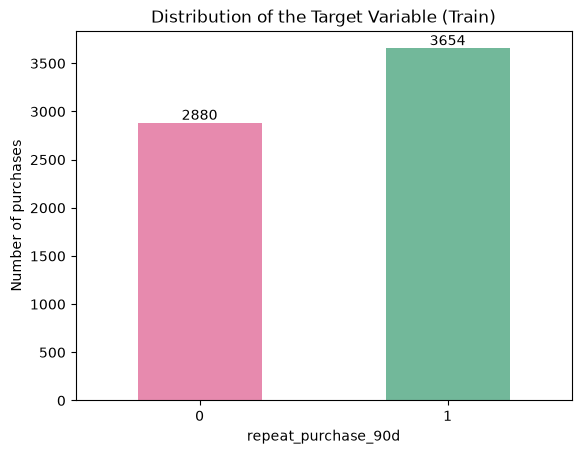

In [13]:
count = train[TARGET].value_counts().sort_index()
proportion = train[TARGET].value_counts(normalize=True).sort_index().round(3)

print(pd.DataFrame({"n": count, "proportion": proportion}))

ax = count.plot(
    kind="bar",
    color=["#E78AAE", "#72B89A"],
    rot=0
)

ax.set_title("Distribution of the Target Variable (Train)")
ax.set_xlabel(TARGET)
ax.set_ylabel("Number of purchases")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

**What we see:**

The target contains approximately 56% positive and 44% negative observations, so the classes are relatively balanced.

We will initially train models without resampling and evaluate their performance using appropriate classification metrics.

### 1.6. Missing values, duplicates and identifiers

A missing value (`NaN`) can arise for very different reasons:
- **error / empty row:** the record is incomplete;
- **structural absence:** the value does not exist by definition (e.g. a customer making their first purchase cannot have a "standard deviation of previous purchases").

Treating both cases the same way would be a mistake, so we first **measure** them.

#### 1.6.1. Missing values by variable (train and test)

In [14]:
missing_train = missing_table(train)

print("=== TRAIN ===")
print(missing_train)

print("\n=== TEST ===")
print(missing_table(test))


=== TRAIN ===
                                n_missing     %
prior_std_gap_days                   1478  22.6
prior_mean_gap_days                  1308  20.0
prior_std_purchase_value             1113  17.0
prior_mean_purchase_value             862  13.2
days_since_previous_purchase          861  13.2
prior_max_purchase_value              668  10.2
prior_min_purchase_value              668  10.2
transport_method                      261   4.0
warehouse                             260   4.0
payment_type                          260   4.0
spend_365d                            260   4.0
salesperson                           259   4.0
Total Imp_                             65   1.0
Total Liquido                          65   1.0
Total Bruto                            65   1.0
Total a Pagar                          65   1.0
customer_tenure_days                   65   1.0
invoice_count_current_purchase         65   1.0
N_ Detalhes                            65   1.0
Total Portes              

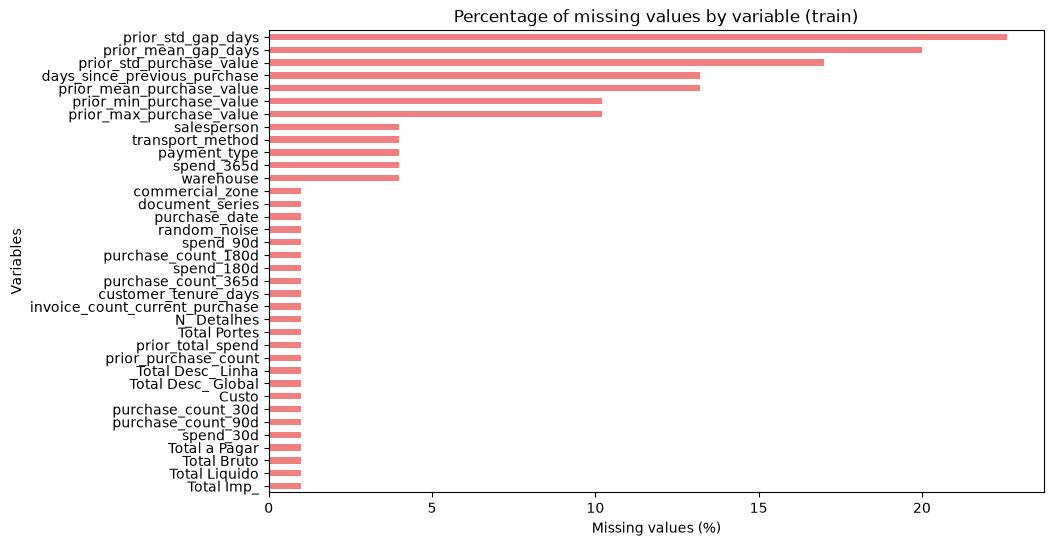

In [15]:
plt.figure(figsize=(10, 6))

missing_train["%"].sort_values().plot(kind="barh", color="lightcoral")
plt.title("Percentage of missing values by variable (train)")
plt.xlabel("Missing values (%)")
plt.ylabel("Variables")
plt.show()

**What we see:** in the training set, many columns have exactly **65** missing values. This recurring number is suspicious: it suggests that the **same 65 rows** are empty everywhere. Let's verify.

#### 1.6.2. Missing values per observation

We also check how missing values are distributed across observations to identify whether some rows have significantly more missing information than others. This is important because some purchases might have almost no information available. We need to identify these observations before deciding whether to keep, fix or remove them.

In [16]:
# Columns that are neither identifiers nor the target
feature_columns = [c for c in train.columns if c not in [TARGET, "ID", "customer_id"]]

# For each row, how many of these columns are missing?
missing_per_row = train[feature_columns].isna().sum(axis=1)

print("Number of missing columns per row (rows with at least one missing value):")
print(missing_per_row[missing_per_row > 0].value_counts().sort_index())

Number of missing columns per row (rows with at least one missing value):
1     1287
2      190
3      354
4      100
5        6
7      511
8       86
9        6
36      65
Name: count, dtype: int64


In [17]:
# Rows where every feature is missing
empty_rows_train = train[feature_columns].isna().all(axis=1)
print("Rows with every feature missing:", empty_rows_train.sum())
print("Target in those rows:", train.loc[empty_rows_train, TARGET].value_counts().to_dict())

train.loc[empty_rows_train, ["ID", "customer_id", TARGET, date_col, "Total a Pagar", "payment_type"]].head()

Rows with every feature missing: 65
Target in those rows: {1: 33, 0: 32}


,ID,customer_id,repeat_purchase_90d,purchase_date,Total a Pagar,payment_type
393,10000457,755628,1,NaN,NaN,NaN
484,10000560,755628,1,NaN,NaN,NaN
582,10000678,427118,1,NaN,NaN,NaN
583,10000679,508217,0,NaN,NaN,NaN
748,10000870,427118,0,NaN,NaN,NaN


**What we see:** **65 training rows are empty** (only `ID`, `customer_id` and the target are filled in) and the target is split 33/32 in them. Without any other variable these rows carry no information, and the test set contains no such rows.

Next, we look at the missing values that remain once these empty rows are set aside, the ones that occur within the "valid" data.

In [18]:
train_ok = train.loc[~empty_rows_train]

print("Train without empty rows:", train_ok.shape, "\n")
print(missing_table(train_ok))

Train without empty rows: (6469, 39) 

                              n_missing     %
prior_std_gap_days                 1413  21.8
prior_mean_gap_days                1243  19.2
prior_std_purchase_value           1048  16.2
prior_mean_purchase_value           797  12.3
days_since_previous_purchase        796  12.3
prior_min_purchase_value            603   9.3
prior_max_purchase_value            603   9.3
transport_method                    196   3.0
spend_365d                          195   3.0
payment_type                        195   3.0
warehouse                           195   3.0
salesperson                         194   3.0


#### 1.6.3. Missing values and previous purchases (structural missingness)

The `prior_std_gap_days`, `prior_mean_gap_days`, `prior_std_purchase_value` columns describe the customer's history. Our hypothesis is that they are missing when the customer has **few prior purchases** to compute them. We first look at `prior_std_purchase_value` by number of previous purchases.

In [19]:
train.groupby("prior_purchase_count")["prior_std_purchase_value"].apply(
    lambda x: x.isnull().mean() * 100
).head(10)

prior_purchase_count
0.0    100.0
1.0    100.0
2.0      0.0
3.0      0.0
4.0      0.0
5.0      0.0
6.0      0.0
7.0      0.0
8.0      0.0
9.0      0.0
Name: prior_std_purchase_value, dtype: float64

- 0 previous purchases → 100% missing: there is no purchase history to compute a standard deviation.
- 1 previous purchase → 100% missing: one purchase is not enough to compute a sample standard deviation.
- 2 or more previous purchases → 0% missing: there is enough information.

We extend the test to all history columns: what share of their missing values occurs for customers with 0 or 1 previous purchases?

In [20]:
prior_cols = ["prior_min_purchase_value", "prior_std_purchase_value", "prior_std_gap_days",
              "prior_mean_gap_days", "prior_mean_purchase_value", "days_since_previous_purchase"]

rows = []
for c in prior_cols:
    is_missing = train_ok[c].isna()
    few_purchases = train_ok.loc[is_missing, "prior_purchase_count"] <= 1
    rows.append({"column": c,
                 "n_missing": int(is_missing.sum()),
                 "% with 0 or 1 previous purchases": round(few_purchases.mean() * 100, 1)})

print(pd.DataFrame(rows).to_string(index=False))
print("\nFirst purchases (prior_purchase_count == 0):", (train["prior_purchase_count"] == 0).sum())

                      column  n_missing  % with 0 or 1 previous purchases
    prior_min_purchase_value        603                             100.0
    prior_std_purchase_value       1048                             100.0
          prior_std_gap_days       1413                              74.2
         prior_mean_gap_days       1243                              84.3
   prior_mean_purchase_value        797                              78.2
days_since_previous_purchase        796                              78.1

First purchases (prior_purchase_count == 0): 603


**What we see:**

- Most missing purchase-history values occur when customers have few previous purchases, suggesting structural missingness.
- However, some missing values also occur for customers with long purchase histories, so not all missingness can be explained by the number of previous purchases.

**Conclusion:** We need to distinguish structural missingness from other missing values during preprocessing.

#### 1.6.4. Duplicates and identifiers

In [21]:
print("Duplicated training rows:", train.duplicated().sum())
print("Duplicated training IDs:", train["ID"].duplicated().sum())
print("Duplicated rows ignoring ID:", train.drop(columns="ID").duplicated().sum())

print("\nUnique customers in train:", train["customer_id"].nunique())
print("Unique customers in test:", test["customer_id"].nunique())

Duplicated training rows: 0
Duplicated training IDs: 0
Duplicated rows ignoring ID: 10

Unique customers in train: 610
Unique customers in test: 206


**What we see:** there are no duplicated rows or repeated `ID`s; each `ID` is a unique purchase observation. The 10 rows that are duplicated when `ID` is ignored are the empty rows of the same customers (only `customer_id` and target filled). About 610 customers generate 6,534 purchases, so **the same customer appears many times**.

#### 1.6.5. Purchases per Customer

Since the same customer can appear multiple times in our dataset, we want to understand how purchases are distributed across customers.

We look at the number of observations per customer to see whether purchasing activity is evenly distributed or concentrated among a smaller group.

Number of customers: 610
Average observations per customer: 10.7
Median observations per customer: 4.0
Maximum observations: 277
Customers with only one observation: 157
Share from top 10% of customers: 50.4%


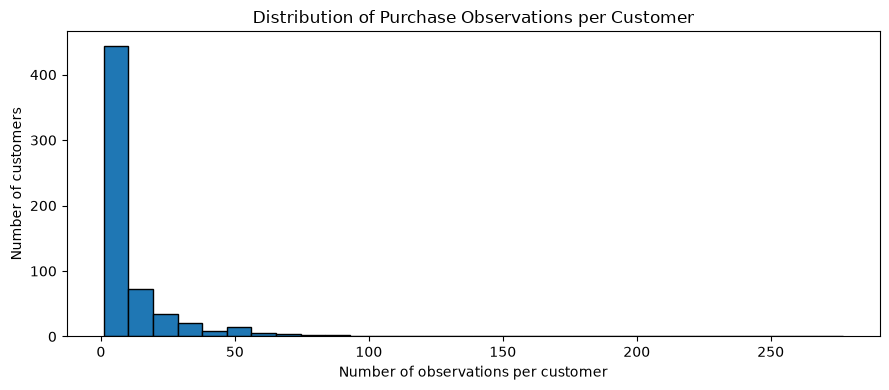

In [22]:
purchases_per_customer = train["customer_id"].value_counts()

# Summary statistics
print("Number of customers:", len(purchases_per_customer))
print("Average observations per customer:", round(purchases_per_customer.mean(), 1))
print("Median observations per customer:", purchases_per_customer.median())
print("Maximum observations:", purchases_per_customer.max())
print("Customers with only one observation:", (purchases_per_customer == 1).sum())

# Share of observations from the most active 10% of customers
top_10 = int(np.ceil(len(purchases_per_customer) * 0.10))
top_10_share = purchases_per_customer.head(top_10).sum() / len(train)

print(f"Share from top 10% of customers: {top_10_share:.1%}")

# Distribution
plt.figure(figsize=(9, 4))
plt.hist(purchases_per_customer, bins=30, edgecolor="black")
plt.title("Distribution of Purchase Observations per Customer")
plt.xlabel("Number of observations per customer")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()


**What we see:**

Most customers have few purchase observations, while a small number appear much more frequently. The top 10% of customers account for 50.4% of all observations.

This shows that purchasing activity is concentrated among a small group of customers, which should be considered during model validation.

### 1.7. Data inconsistencies and anomalous values

We now look for values that are impossible or unrealistic, such as negative time intervals or extremely large amounts.
This helps us identify possible data quality issues that may need to be addressed during preprocessing.

#### 1.7.1. Minimum and maximum values

In [23]:
train.select_dtypes(include="number").agg(["min", "max"]).T.round(2)

,min,max
Total a Pagar,0.93,2.229721e+04
Total Bruto,0.83,2.157828e+04
Total Liquido,0.76,1.812781e+04
Total Imp_,0.00,4.169400e+03
Total Portes,0.00,1.810600e+02
Total Desc_ Global,0.00,2.184900e+02
Total Desc_ Linha,0.00,4.103440e+03
Custo,0.00,7.427400e+03
N_ Detalhes,1.00,4.230000e+02
invoice_count_current_purchase,1.00,5.000000e+00


The minimum and maximum values reveal suspicious observations:
- **Negative time intervals:** `days_since_previous_purchase` and `prior_mean_gap_days` have a minimum of -4, but the time between purchases cannot be negative.
- **Negative monetary values:** `prior_mean_purchase_value` (-2,478.66) and `spend_365d` (-159,115.20) – errors, refunds or accounting adjustments.
- **Extremely large values:** `prior_mean_purchase_value` and `spend_365d` reach 1,000,000,000, unrealistic compared with typical purchase amounts.

#### 1.7.2. Negative values

In [24]:
variables = ["days_since_previous_purchase", "prior_mean_gap_days",
             "prior_mean_purchase_value", "spend_365d"]
(train[variables] < 0).sum()

days_since_previous_purchase    16
prior_mean_gap_days             16
prior_mean_purchase_value       16
spend_365d                      15
dtype: int64

We found a small number of negative values in four variables. These values seem unusual, especially for the time between purchases, and may indicate data errors.

#### 1.7.3. Extremely large values

In [25]:
print("Rows with a value >= 1e8:")
print((train[["prior_mean_purchase_value", "spend_365d"]] >= 1e8).sum())

train[["prior_mean_purchase_value", "spend_365d"]].sort_values(by="spend_365d", ascending=False).head(10)

Rows with a value >= 1e8:
prior_mean_purchase_value    16
spend_365d                   15
dtype: int64


,prior_mean_purchase_value,spend_365d
3514,615.926667,1.000000e+09
2356,870.590000,1.000000e+09
2369,2114.369286,1.000000e+09
4155,1196.175094,1.000000e+09
4395,977.420000,1.000000e+09
1630,NaN,1.000000e+09
3324,154.767826,1.000000e+09
1029,902.712018,1.000000e+09
5851,1801.632857,1.000000e+09
2590,828.988529,1.000000e+09


These extremely large values are unlikely to represent genuine purchases and may be sentinel values or data errors. We will handle them during preprocessing.

#### 1.7.4. Numerical consistency checks

We also want to check whether related numerical variables are consistent with each other.

For example, transaction amounts should follow the expected calculations, and purchase counts over longer periods should be at least as large as those over shorter periods.

These checks can help us identify possible errors that were not detected by simply looking at minimum and maximum values.

In [26]:
# • Check Numerical Consistency

# Exclude completely empty purchase observations
d = train.dropna(subset=["Total a Pagar"])

# Check transaction calculations
check_total = np.isclose(
    d["Total a Pagar"],
    d["Total Liquido"] + d["Total Imp_"],
    atol=0.05
)

check_net = np.isclose(
    d["Total Liquido"],
    d["Total Bruto"] - d["Total Desc_ Linha"] - d["Total Desc_ Global"],
    atol=0.05
)

# Check purchase counts across time windows
check_counts = (
    (d["purchase_count_30d"] <= d["purchase_count_90d"]) &
    (d["purchase_count_90d"] <= d["purchase_count_180d"]) &
    (d["purchase_count_180d"] <= d["purchase_count_365d"])
)

# Check spending across time windows where values are available
spend_data = d.dropna(subset=["spend_180d", "spend_365d"])

check_spend = (
    spend_data["spend_180d"] <= spend_data["spend_365d"] + 0.01
)

# Check Maximum Previous Purchase Against Total Spending

check_max = (
    (d["prior_max_purchase_value"] <= d["prior_total_spend"] + 0.01)
    | d["prior_max_purchase_value"].isna()
)


# Summarize the results

consistency = pd.DataFrame({
    "Rule": [
        "Amount paid = Net amount + Taxes",
        "Net amount = Gross amount - Discounts",
        "Purchase counts: 30d <= 90d <= 180d <= 365d",
        "Spending: 180d <= 365d",
        "Prior max <= prior total spend"
    ],
    "Rows Checked": [
        len(d), len(d), len(d), len(spend_data), len(d)
    ],
    "Violations": [
        (~check_total).sum(),
        (~check_net).sum(),
        (~check_counts).sum(),
        (~check_spend).sum(),
        (~check_max).sum()
    ]
})

display(consistency)


,Rule,Rows Checked,Violations
0,Amount paid = Net amount + Taxes,6469,0
1,Net amount = Gross amount - Discounts,6469,0
2,Purchase counts: 30d <= 90d <= 180d <= 365d,6469,0
3,Spending: 180d <= 365d,6274,15
4,Prior max <= prior total spend,6469,45


**What we see:**

The transaction calculations and purchase counts are consistent.

However, we found 15 inconsistencies in historical spending and 45 cases where the maximum previous purchase exceeds the total historical spending.

We will investigate these values during preprocessing.

### 1.8. Consistency of categorical variables

Text categories may be written inconsistently (accents, upper/lower case, extra spaces). We normalise them and check whether the number of levels changes. We also count how many test rows use a level that never appears in training, since the model cannot learn anything about those.

In [27]:
train_normalized = normalize_string_columns(train)

pd.DataFrame({
    "levels_original": train[CATEGORICAL].nunique(),
    "levels_normalized": train_normalized[CATEGORICAL].nunique(),
    "test_rows_with_unseen_level": [
        (~test[c].dropna().isin(train[c].dropna())).sum()
        for c in CATEGORICAL
    ],
})


,levels_original,levels_normalized,test_rows_with_unseen_level
payment_type,9,9,3
salesperson,9,9,0
commercial_zone,5,5,209
transport_method,80,80,63
warehouse,2,2,7
document_series,3,3,0


**What we see:**
- Normalisation does not change the number of levels, so the categories are written consistently.
- Several test rows use levels never seen in training (e.g. 209 for `commercial_zone`, 63 for `transport_method`).

### 1.9. Train vs. test: time periods and drift

The `purchase_date` column is stored as text. We convert it to a date to compare when the training and test purchases happen.

In [28]:
# errors="coerce": invalid dates become NaT instead of raising an error
train_dates = pd.to_datetime(train[date_col], errors="coerce")
test_dates = pd.to_datetime(test[date_col], errors="coerce")

print("Train period:", train_dates.min().date(), "to", train_dates.max().date())
print("Test period :", test_dates.min().date(), "to", test_dates.max().date())

# Number of purchases per year, train vs test
print(pd.DataFrame({"train": train_dates.dt.year.value_counts().sort_index(),
                    "test": test_dates.dt.year.value_counts().sort_index()}).fillna(0).astype(int))

Train period: 2015-07-11 to 2025-02-15
Test period : 2025-05-24 to 2026-10-06
               train  test
purchase_date             
2015.0           335     0
2016.0           420     0
2017.0           670     0
2018.0           716     0
2019.0           646     0
2020.0           670     0
2021.0           782     0
2022.0           628     0
2023.0           767     0
2024.0           757     0
2025.0            78   465
2026.0             0   521


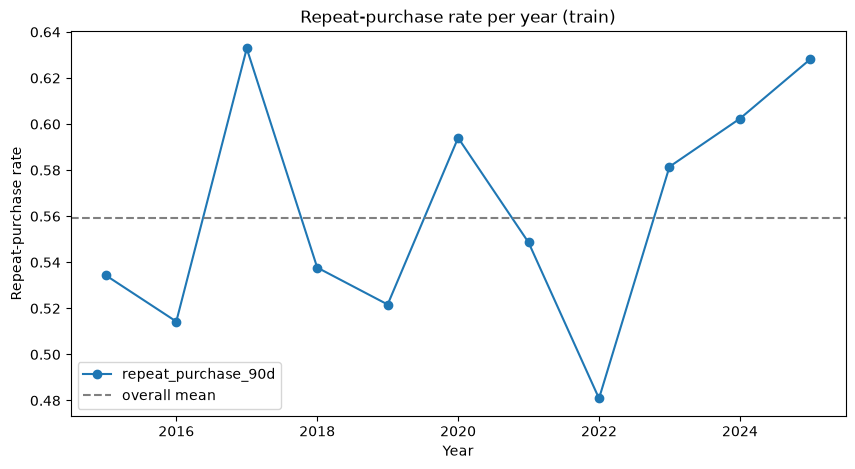

,train_median,test_median
customer_tenure_days,918.00,2662.00
prior_purchase_count,11.00,28.00
prior_total_spend,6754.31,25186.53
purchase_count_365d,3.00,4.00
days_since_previous_purchase,57.00,59.00


In [29]:
# Repeat-purchase rate per year (train only)
yearly_rate = train.groupby(train_dates.dt.year)[TARGET].mean()

ax = yearly_rate.plot(marker="o", figsize=(10, 5))
ax.axhline(train[TARGET].mean(), color="gray", linestyle="--", label="overall mean")
ax.set(title="Repeat-purchase rate per year (train)", xlabel="Year", ylabel="Repeat-purchase rate")
ax.legend()
plt.show()

# Do customers look the same in train and test?
pd.DataFrame({"train_median": train.median(numeric_only=True),
              "test_median": test.median(numeric_only=True)}).loc[
    ["customer_tenure_days", "prior_purchase_count", "prior_total_spend",
     "purchase_count_365d", "days_since_previous_purchase"]]

**What we see:**

- Training purchases range from July 2015 to February 2025, while test purchases range from May 2025 to October 2026.
- The repeat-purchase rate varies over the years, without a clear trend.
- Test observations generally show higher customer tenure, previous purchase counts and spending. This may be partly explained by the later time period, although differences in the customer population could also contribute.

These differences support using a chronological validation split to better reflect future predictions. Since our target looks at purchases within the following 90 days, we leave a 90-day gap between training and validation to avoid overlap between the training labels' future observation period and the validation period.

### 1.10. Univariate distributions

We explore the distributions of some numerical and categorical variables with histograms, boxplots and countplots, to understand purchasing behaviour and identify outliers.

#### 1.10.1. Overview of Numerical Distributions

We first look at the distributions of all numerical variables to get a general idea of their behaviour.

This helps us identify skewed distributions, extreme values and variables with a large concentration of observations around zero.

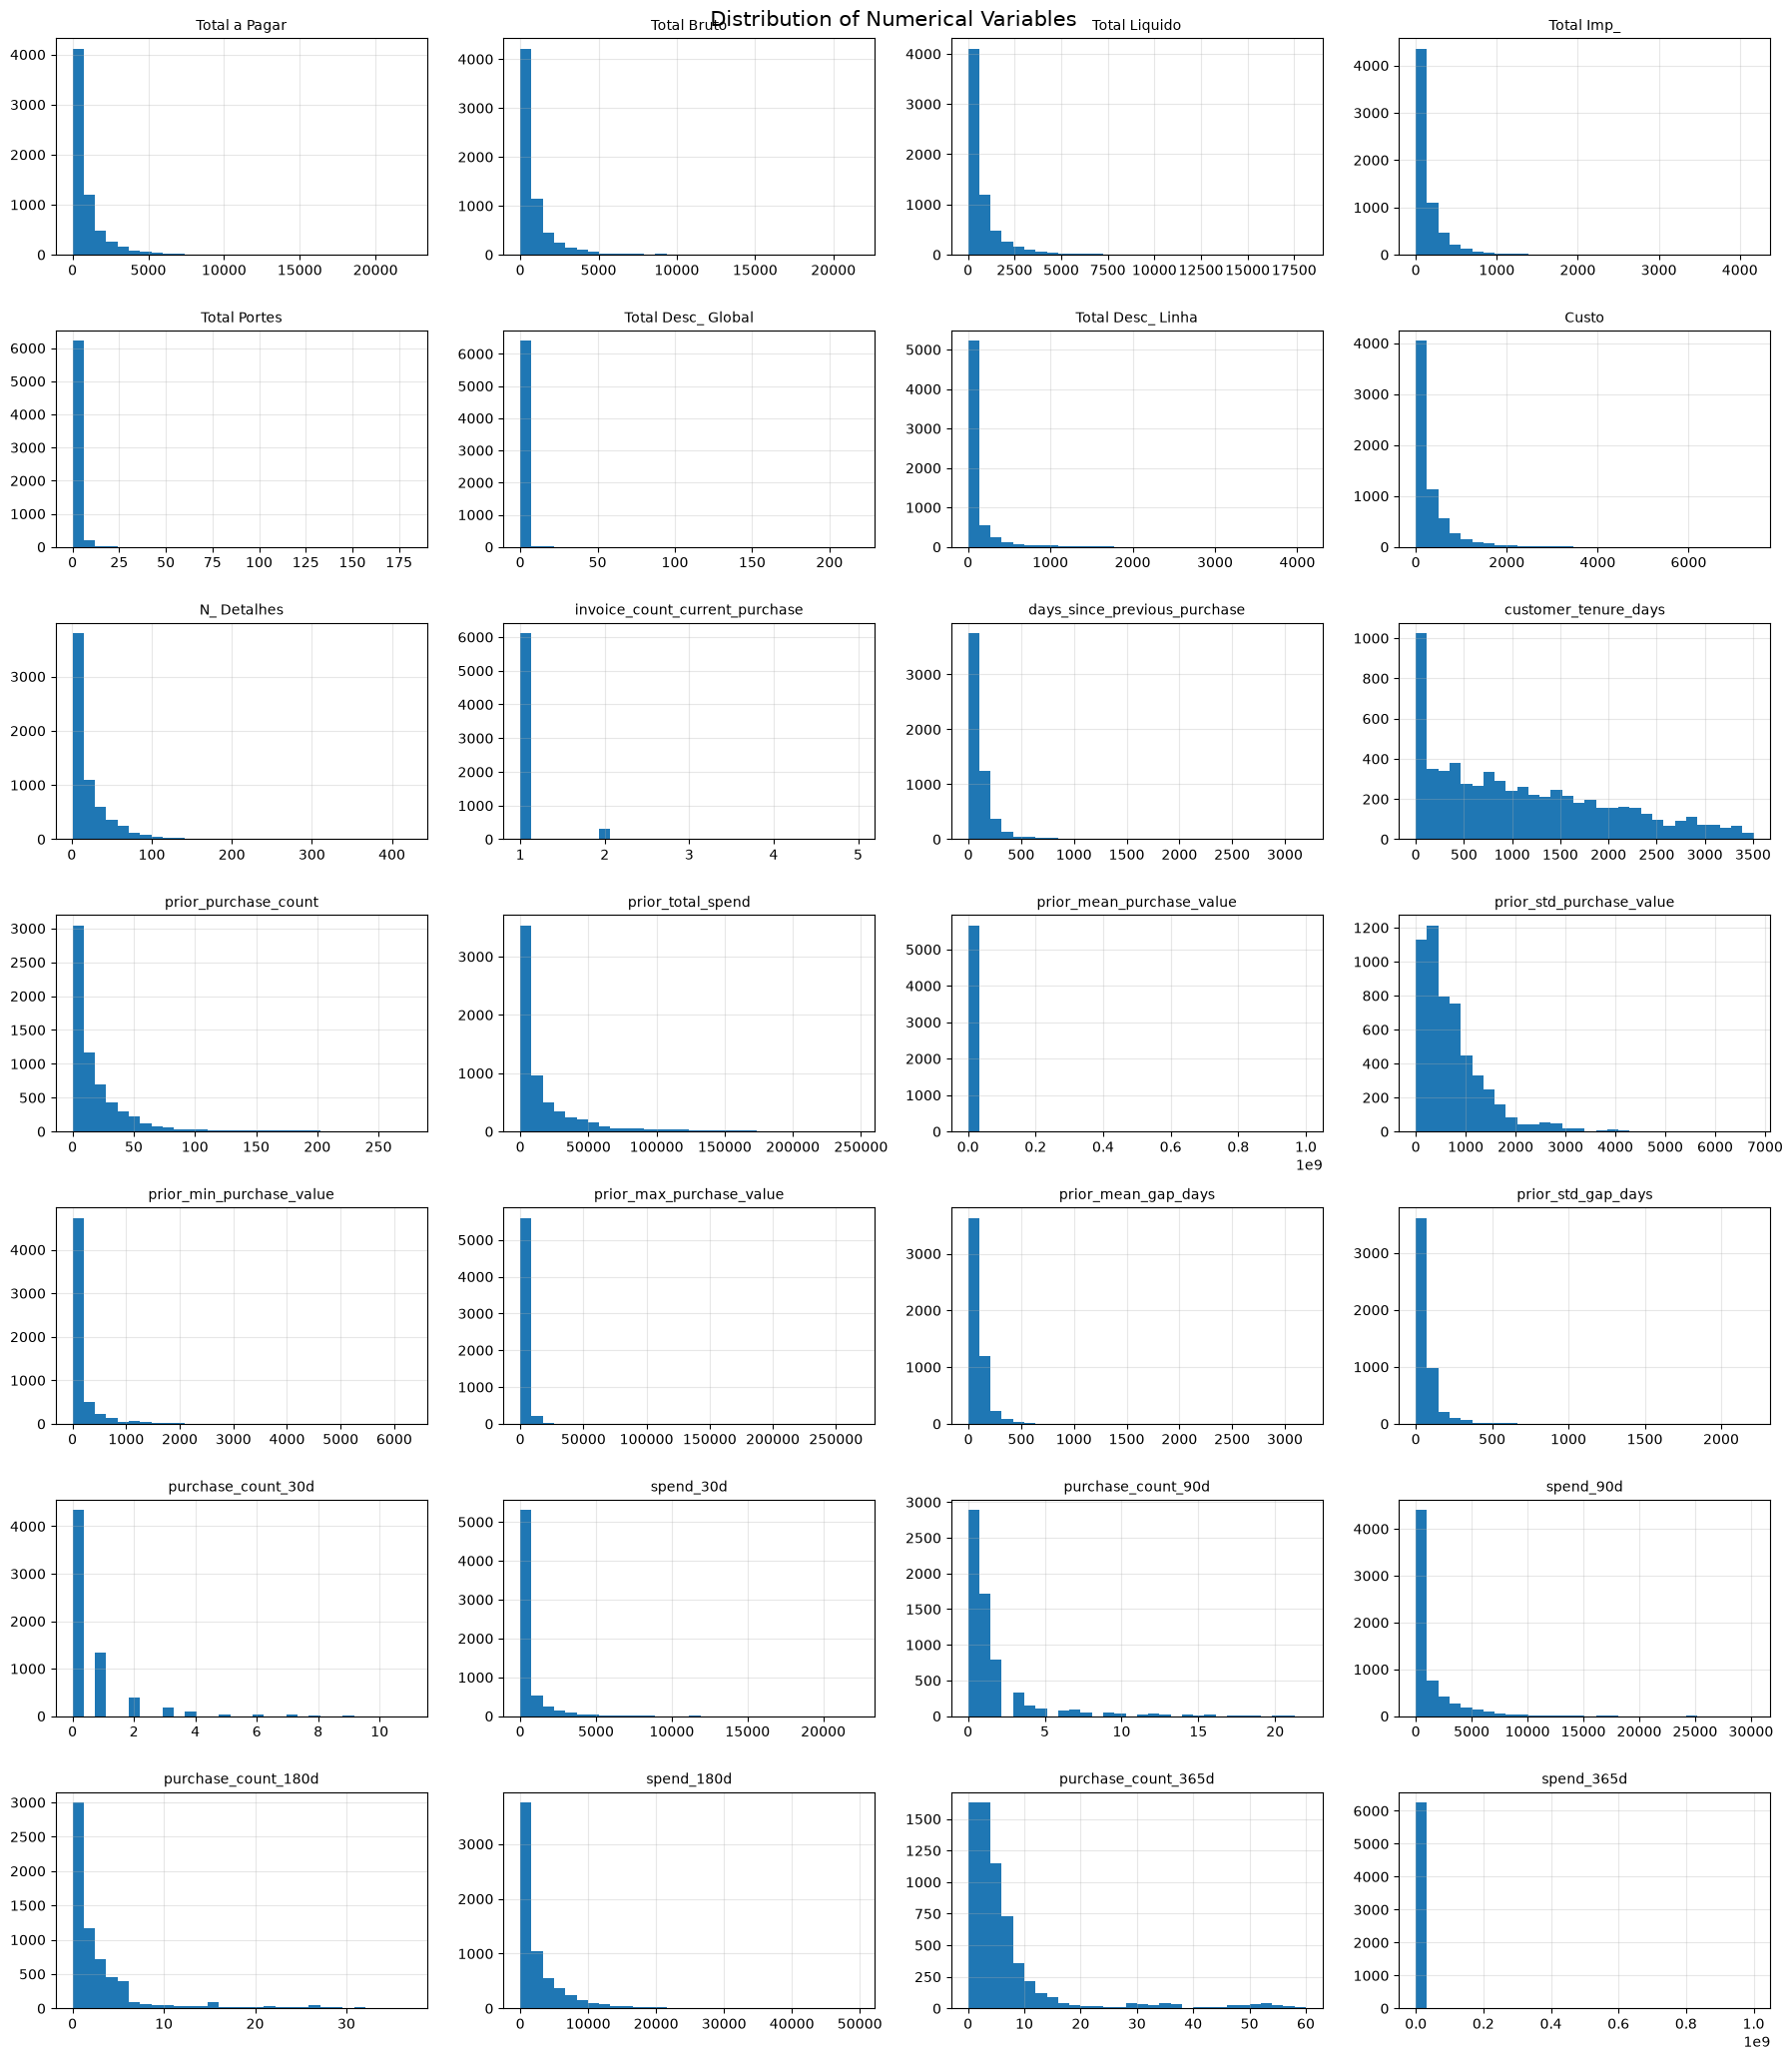

In [30]:
# • Plot Distributions of Numerical Variables

numeric_data = train.select_dtypes(include="number").drop(
    columns=["ID", "customer_id", "random_noise", "repeat_purchase_90d"],
    errors="ignore"
)

n_cols = 4
n_rows = int(np.ceil(len(numeric_data.columns) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(numeric_data.columns):
    axes[i].hist(numeric_data[col].dropna(), bins=30)
    axes[i].set_title(col, fontsize=10)
    axes[i].grid(alpha=0.3)

# Hide unused plots
for j in range(len(numeric_data.columns), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Distribution of Numerical Variables", fontsize=15)
plt.tight_layout()
plt.show()


**What we see:**

Most purchase amounts, spending variables and purchase counts are right-skewed, with observations concentrated at lower values. Customer tenure is more spread out.

The 28 histograms exclude identifiers, the target and `random_noise`.

#### 1.10.2. Purchase amount

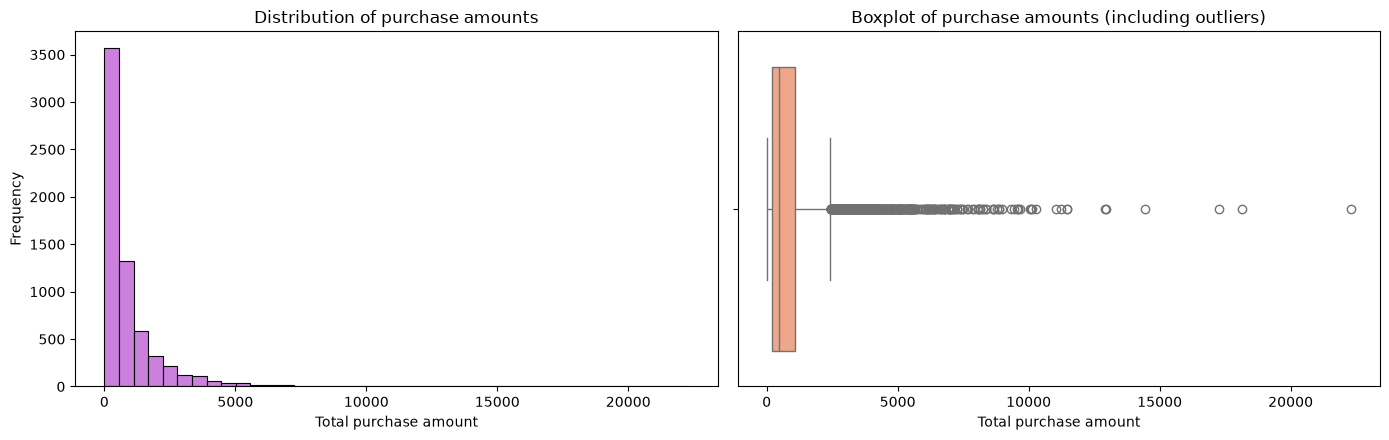

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(data=train, x="Total a Pagar", bins=40, color="mediumorchid", ax=axes[0])
axes[0].set(title="Distribution of purchase amounts", xlabel="Total purchase amount", ylabel="Frequency")

sns.boxplot(data=train, x="Total a Pagar", color="lightsalmon", ax=axes[1])
axes[1].set(title="Boxplot of purchase amounts (including outliers)", xlabel="Total purchase amount")

plt.tight_layout()
plt.show()

Most purchases have relatively low amounts, while a few are much larger (some above 20,000), producing a strongly **right-skewed** distribution with many outliers.

#### 1.10.3. Payment types

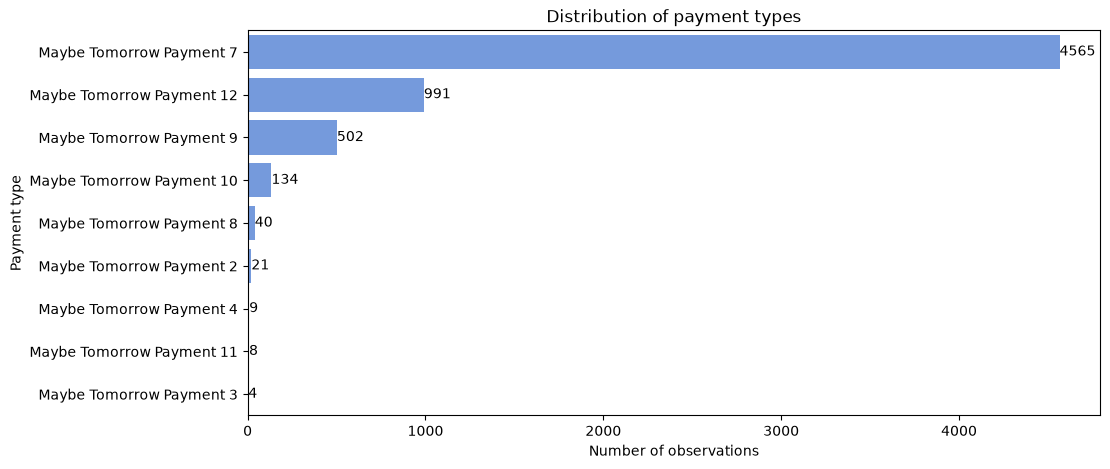

In [32]:
plt.figure(figsize=(11, 5))
ax = sns.countplot(data=train, y="payment_type",
                   order=train["payment_type"].value_counts().index, color="cornflowerblue")
plt.title("Distribution of payment types")
plt.xlabel("Number of observations")
plt.ylabel("Payment type")
for container in ax.containers:
    ax.bar_label(container)
plt.show()

Payment Type 7 is by far the most common, followed by Payment Types 12 and 9. The remaining categories are rare, so payment types are far from equally distributed.

#### 1.10.4. Other Categorical Distributions

We now look at the distributions of the remaining categorical variables to see which categories are most common and whether some appear very rarely.

For variables with many categories, we display only the 10 most frequent ones to keep the graphs readable.

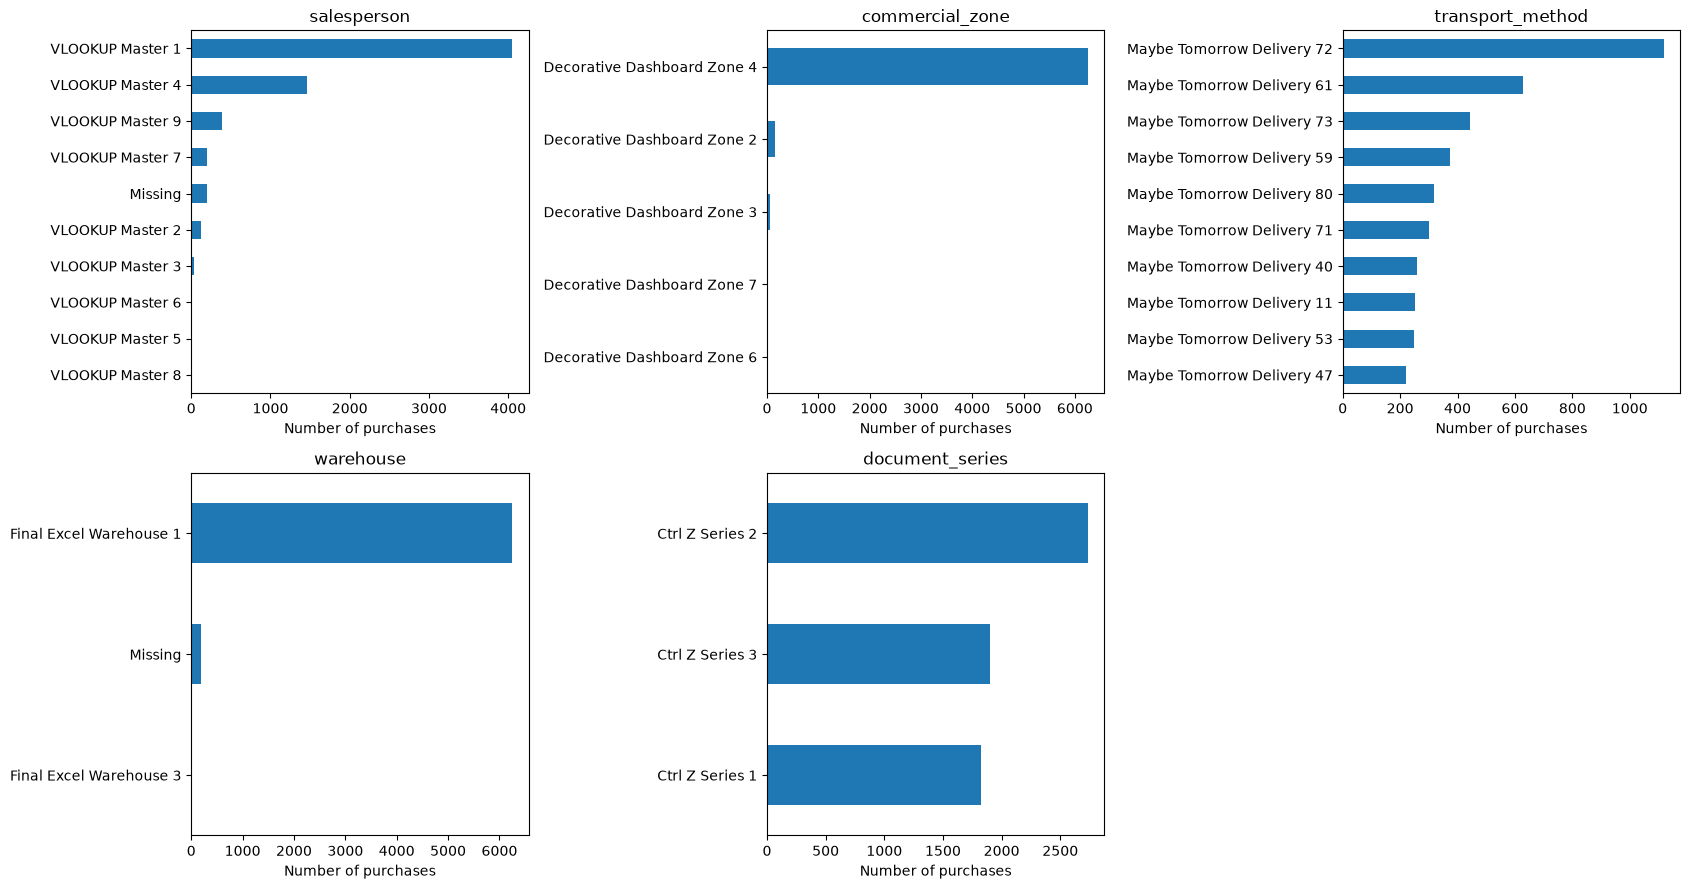

In [33]:
# • Plot Distributions of Categorical Variables

categorical_cols = [
    "salesperson",
    "commercial_zone",
    "transport_method",
    "warehouse",
    "document_series"
]

# Exclude the 65 observations with no purchase information
plot_data = train.dropna(subset=["Total a Pagar"])

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    counts = plot_data[col].fillna("Missing").value_counts()

    counts.head(10).sort_values().plot.barh(ax=axes[i])

    axes[i].set_title(col)
    axes[i].set_xlabel("Number of purchases")
    axes[i].set_ylabel("")

# Hide the unused subplot
axes[-1].set_visible(False)

plt.tight_layout()
plt.show()


**What we see:**

- `commercial_zone` and `warehouse` are dominated by one category, representing almost 97% of purchases.
- `salesperson` also has an uneven distribution, with one category appearing much more frequently than the others.
- `transport_method` has many different categories, some with very few observations.
- `document_series` has a more balanced distribution across its three categories.

These results suggest that some categorical variables may provide limited information, while others contain many rare categories. We will take this into account during preprocessing and feature selection.

### 1.11. Relationships with the target

We now explore how the variables relate to `repeat_purchase_90d`, to identify patterns that may help predict whether a customer purchases again within 90 days.

#### 1.11.1. Numerical variables vs. target

Median prior_purchase_count by class:
repeat_purchase_90d
0     6.0
1    17.0
Name: prior_purchase_count, dtype: float64


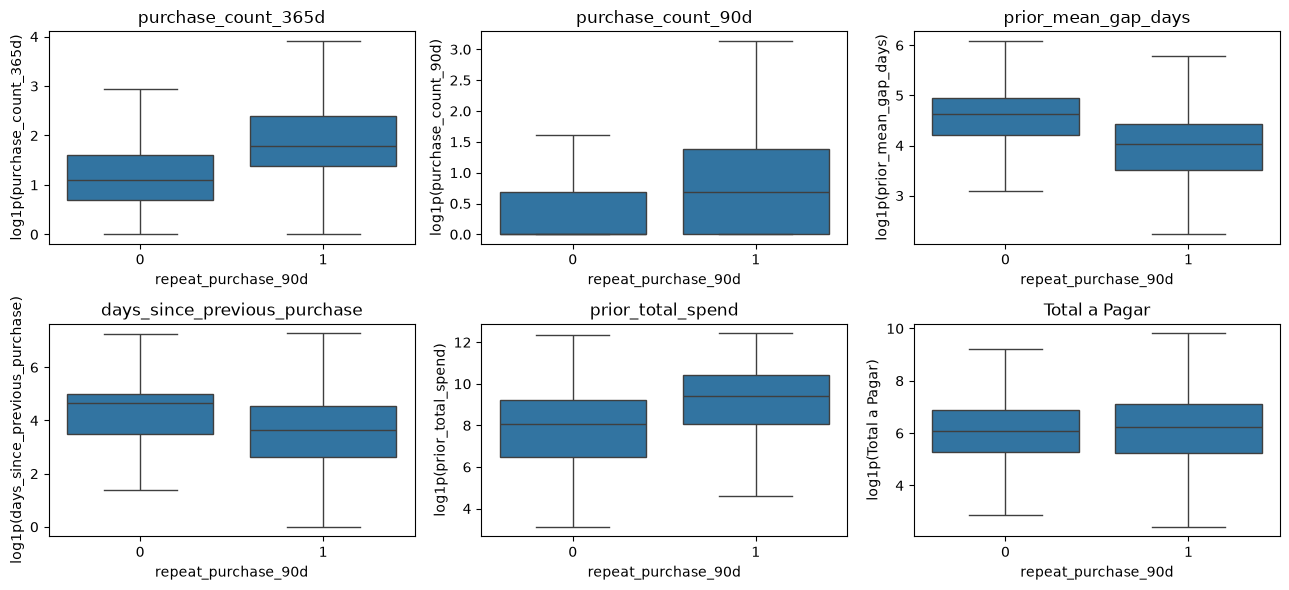

In [34]:
print("Median prior_purchase_count by class:")
print(train.groupby(TARGET)["prior_purchase_count"].median())

key_numeric = ["purchase_count_365d", "purchase_count_90d", "prior_mean_gap_days",
               "days_since_previous_purchase", "prior_total_spend", "Total a Pagar"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, col in zip(axes.ravel(), key_numeric):
    # clip and log1p are applied only for this plot, to make the skewed values readable
    sns.boxplot(data=train, x=TARGET, y=np.log1p(train[col].clip(lower=0, upper=1e7)), ax=ax, showfliers=False)
    ax.set(title=col, ylabel=f"log1p({col})")
plt.tight_layout()
plt.show()

**What we see:**
- Customers who purchase again within 90 days have many more previous purchases (median 17 vs. 6).
- Customers who **buy often** (high `purchase_count_*`) and have **short historical gaps** (low `prior_mean_gap_days`, `days_since_previous_purchase`) are much more likely to buy again: **frequency and recency are the main signal**.
- The value of the current purchase (`Total a Pagar`) hardly separates the classes.

#### 1.11.2. First Purchases vs. Previous Purchase History

We compare the repeat-purchase rate of customers with no previous purchases and those with an existing purchase history.

In [35]:
history_comparison = train_ok.copy()

history_comparison["Purchase History"] = np.where(
    history_comparison["prior_purchase_count"] == 0,
    "No previous purchases",
    "Has previous purchases"
)

history_rates = history_comparison.groupby("Purchase History")[TARGET].agg(
    Observations="size",
    Repeat_Rate="mean"
)

history_rates["Repeat_Rate"] = (history_rates["Repeat_Rate"] * 100).round(1)

display(history_rates)


,Observations,Repeat_Rate
Purchase History,,
Has previous purchases,5866,58.3
No previous purchases,603,33.3


**What we see:**

Observations with previous purchase history have a higher repeat-purchase rate (58.3%) than those without previous purchases (33.3%).

This supports our earlier finding that purchasing history is an important predictor.

#### 1.11.3. Categorical variables vs. target

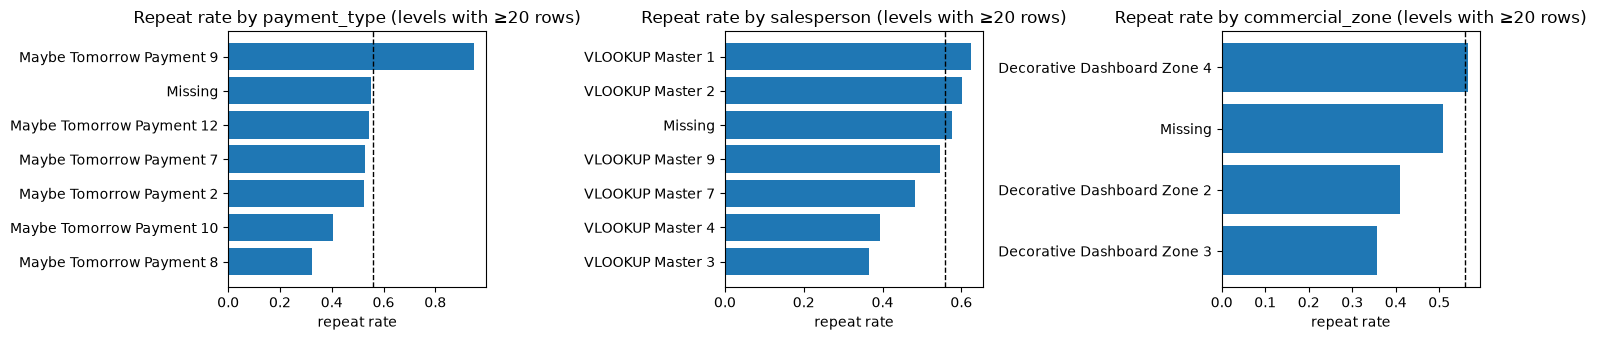

,repeat_rate_pct,n
payment_type,,
Maybe Tomorrow Payment 9,95.0,502
Maybe Tomorrow Payment 11,62.5,8
Missing,55.0,260
Maybe Tomorrow Payment 12,54.3,991
Maybe Tomorrow Payment 7,52.7,4565
Maybe Tomorrow Payment 2,52.4,21
Maybe Tomorrow Payment 3,50.0,4
Maybe Tomorrow Payment 4,44.4,9
Maybe Tomorrow Payment 10,40.3,134


In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["payment_type", "salesperson", "commercial_zone"]):
    rate = train.groupby(train[col].fillna("Missing"))[TARGET].agg(["mean", "size"])
    rate = rate[rate["size"] >= 20].sort_values("mean")
    ax.barh(rate.index, rate["mean"])
    ax.axvline(train[TARGET].mean(), color="black", ls="--", lw=1)
    ax.set(title=f"Repeat rate by {col} (levels with ≥20 rows)", xlabel="repeat rate")
plt.tight_layout()
plt.show()

# Exact repeat rate (%) and size of each payment type
train.groupby(train["payment_type"].fillna("Missing"))[TARGET].agg(
    repeat_rate_pct=lambda s: round(s.mean() * 100, 1), n="size"
).sort_values("repeat_rate_pct", ascending=False)

**What we see:**

Repeat-purchase rates vary considerably between categories. For example, Payment Type 9 has a repeat rate of approximately 95%, compared with 32% for Payment Type 8.

This suggests that some categorical variables may be useful predictors. However, these relationships need to be validated, especially for categories with few observations.

#### 1.11.4. Correlations (Spearman)

We use **Spearman** correlation because it is based on ranks and is therefore robust to the skewness and extreme values identified above.

purchase_count_365d             0.437
purchase_count_180d             0.406
purchase_count_90d              0.393
spend_365d                      0.386
spend_90d                       0.359
prior_purchase_count            0.346
prior_total_spend               0.332
purchase_count_30d              0.261
Total Imp_                      0.081
Total Bruto                     0.078
Total a Pagar                   0.053
Total Liquido                   0.050
random_noise                   -0.008
Custo                          -0.013
days_since_previous_purchase   -0.311
prior_mean_gap_days            -0.417
Name: repeat_purchase_90d, dtype: float64


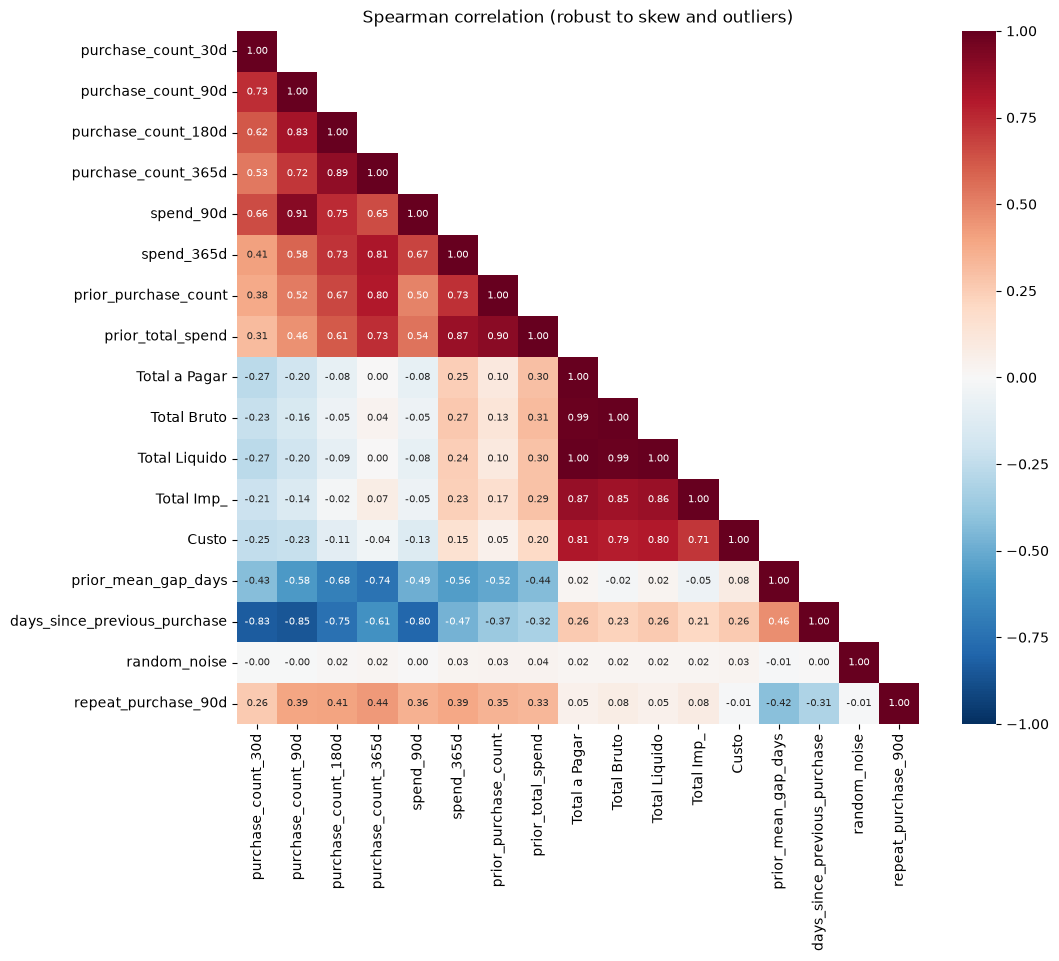

In [37]:
corr_cols = ["purchase_count_30d", "purchase_count_90d", "purchase_count_180d", "purchase_count_365d",
             "spend_90d", "spend_365d", "prior_purchase_count", "prior_total_spend",
             "Total a Pagar", "Total Bruto", "Total Liquido", "Total Imp_", "Custo",
             "prior_mean_gap_days", "days_since_previous_purchase", "random_noise", TARGET]
spearman = train[corr_cols].corr(method="spearman")

# Correlation of each variable with the target, ranked
print(spearman[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

mask = np.triu(np.ones_like(spearman, dtype=bool), k=1)
plt.figure(figsize=(11, 9))
sns.heatmap(spearman, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Spearman correlation (robust to skew and outliers)")
plt.show()

**What we see:**

- Purchase counts are positively correlated with repeat purchasing, while longer gaps between purchases show negative correlations.
- Several transaction amounts and purchase-history variables are strongly correlated with each other, suggesting some redundant information.
- `random_noise` shows almost no correlation with the target.

We will consider these relationships during feature selection.

### 1.12. The auxiliary `clientes.csv` table

#### Customer Information and Repeat Purchases

We compare repeat-purchase rates across commercial regions and customer registration years to see whether these variables might provide useful information for prediction.

In [38]:
customer_eda = train[["customer_id", TARGET]].merge(
    clientes[["customer_id", "commercial_region", "customer_since_year"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

for col in ["commercial_region", "customer_since_year"]:
    rates = customer_eda.groupby(col, dropna=False)[TARGET].agg(
        n="size",
        repeat_rate="mean"
    )

    rates = rates[rates["n"] >= 20].copy()
    rates["repeat_rate"] = (rates["repeat_rate"] * 100).round(1)

    print(f"\nRepeat purchase rate (%) by {col}")
    display(rates.sort_values("repeat_rate", ascending=False))



Repeat purchase rate (%) by commercial_region


,n,repeat_rate
commercial_region,,
Region RG24: We Will See Later,235,94.5
Region RG23: We Will See Later,564,82.4
Region RG19: We Will See Later,77,66.2
Region RG27: We Will See Later,194,64.9
Region RG34: We Will See Later,68,63.2
Region RG18: We Will See Later,368,62.0
Region RG25: We Will See Later,30,53.3
Region RG17: We Will See Later,4109,51.9
Region RG29: We Will See Later,214,50.5



Repeat purchase rate (%) by customer_since_year


,n,repeat_rate
customer_since_year,,
2017,885,66.8
2023,108,60.2
2015,3573,59.5
2016,605,56.7
2020,273,49.1
2019,278,42.8
2021,208,36.5
2018,467,34.9
2024,26,30.8


**What we see:**

- `clientes.csv` contains additional customer information that could be useful for prediction.
- `commercial_region` has 37 categories, while `customer_since_year` contains 12 different years.
- Repeat-purchase rates vary across commercial regions and registration years, suggesting that these variables may contain useful information.
- Some categories have very few observations, so their results should be interpreted carefully.

**Conclusion:** We will include `commercial_region` and `customer_since_year` as candidates during preprocessing and evaluate their usefulness during feature selection.

### 1.13. Summary of the Exploratory Analysis

The EDA helped us identify the main issues that need to be addressed before modelling. The table below summarizes our findings and the decisions we will take during preprocessing.

| Topic | Main Finding | Decision |
|---|---|---|
| **Target** | Around 56% positive observations. | Use classification metrics and compare against a simple baseline. |
| **Missing values** | 65 rows with all predictive features missing. | Exclude rows without a valid purchase date; handle structural missingness separately. |
| **Anomalies** | Negative gaps and incorrect spending values. | Correct values where possible and treat remaining invalid values as missing. |
| **Customer activity** | A small group of customers accounts for many purchases. | Consider repeated customers when validating the model. |
| **Categorical variables** | Some categories are rare, and some appear only in test data. | Use One-Hot Encoding and handle infrequent or unseen categories. |
| **Time periods** | Test observations occur later than training observations. | Use chronological validation with a 90-day gap. |
| **Numerical distributions** | Most financial and purchasing variables are right-skewed. | Investigate extreme values without automatically removing them. |
| **Purchase history** | Frequency and recency are strongly associated with repeat purchasing. | Keep these variables as candidates for feature selection and engineering. |
| **Identifiers** | `ID`, `customer_id` and `random_noise` are not suitable predictors. | Exclude them from the model features. |
| **`clientes.csv`** | Contains additional customer information, but many columns are identifier-like. | Integrate selected customer attributes. |

These findings will guide the Cleaning and Preprocessing stage, where we prepare consistent datasets for training, validation and testing.

# 2. Cleaning and Preprocessing

After exploring the datasets, we now clean and prepare the data for modelling. We apply the same cleaning rules to training and test data, while fitting imputation, scaling and encoding only on the training split to avoid data leakage.

This section covers:

   - **2.1.** Missing Purchase History.
   - **2.2.** Correcting Anomalous Values.
   - **2.3.** Integrating Customer Information.
   - **2.4.** Feature Engineering.
   - **2.5.** Chronological Training and Validation Split.
   - **2.6.** Fitting the Preprocessing Pipeline.
   - **2.7.** Preparing the Test Data.
   - **2.8.** Final Checks.

We reuse the datasets loaded during EDA, avoiding unnecessary imports and data-loading steps.

### 2.1. Missing Purchase History

When customers have little purchase history, some statistics cannot be calculated. We fill these **structurally undefined values** with zero only when justified by the available purchase counts, and add indicators for missing information. Other missing values are left for the fitted imputer. The 65 records with no purchase date are excluded when forming the chronological split, not here.

In [39]:
# Handle Missing Purchase History

train_clean = clean_missing_history(train)
test_clean = clean_missing_history(test)

history_cols = ["prior_std_purchase_value", "prior_std_gap_days"]
print("Training rows preserved:", len(train_clean) == len(train))
print("Test rows preserved:", len(test_clean) == len(test))
display(pd.DataFrame({
    "Missing before": train[history_cols].isna().sum(),
    "Missing after": train_clean[history_cols].isna().sum()
}))

Training rows preserved: True
Test rows preserved: True


,Missing before,Missing after
prior_std_purchase_value,1113,65
prior_std_gap_days,1478,65


**What we see:**

- Missing values in `prior_std_purchase_value` decreased from 1,113 to 65, and in `prior_std_gap_days` from 1,478 to 65.
- The remaining 65 missing values belong to observations without usable purchase information, which will be excluded later.
- All training and test rows are preserved at this stage.

Other missing values will be handled by the preprocessing pipeline.

### 2.2. Correcting Anomalous Values

We correct the invalid values identified during EDA, including negative time gaps, negative annual spending and extreme placeholder values.

We also recalculate previous average purchase values using the customer's total historical spending and purchase count.

Finally, we replace inconsistent maximum previous purchase values with missing values, rather than guessing their correct amount. These will be handled later by the preprocessing pipeline.

In [40]:
# Correct Invalid Purchase-History Values

train_clean = clean_anomalies(train_clean)
test_clean = clean_anomalies(test_clean)

print("Negative annual spending flagged (train):", train_clean["spend_365d_negative"].sum())
# Verify Negative Purchase Gaps

for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
    print(col, "negative values remaining:", (train_clean[col] < 0).sum())

# Verify Maximum Purchase Corrections

print(
    "Inconsistent maximum purchases remaining (train):",
    (train_clean["prior_max_purchase_value"] >
     train_clean["prior_total_spend"] + 0.01).sum()
)

print(
    "Inconsistent maximum purchases remaining (test):",
    (test_clean["prior_max_purchase_value"] >
     test_clean["prior_total_spend"] + 0.01).sum()
)


Negative annual spending flagged (train): 15
days_since_previous_purchase negative values remaining: 0
prior_mean_gap_days negative values remaining: 0
Inconsistent maximum purchases remaining (train): 0
Inconsistent maximum purchases remaining (test): 0


**What we see:**

- 15 observations with negative annual spending were flagged.
- No negative purchase gaps remain after cleaning.
- Suspicious values are replaced with missing values, while historical averages are recalculated where possible.

The remaining missing values will be handled by the preprocessing pipeline.

### 2.3. Integrating Customer Information

We add **`commercial_region`** and **`customer_since_year`** from `clientes.csv` using `customer_id`. Other customer-table fields are not included because some are highly incomplete or identifier-like. The many-to-one left join must preserve all purchase observations.

In [41]:
# Merge Selected Customer Attributes

assert clientes["customer_id"].is_unique, "Expected one row per customer."
train_clean = merge_customer_info(train_clean, clientes)
test_clean = merge_customer_info(test_clean, clientes)

print("Training observations after join:", len(train_clean))
print("Test observations after join:", len(test_clean))
# Check Customer Data Coverage

print("Train coverage:", train["customer_id"].isin(clientes["customer_id"]).mean())
print("Test coverage:", test["customer_id"].isin(clientes["customer_id"]).mean())

Training observations after join: 6534
Test observations after join: 986
Train coverage: 1.0
Test coverage: 1.0


**What we see:**

- We added `commercial_region` and `customer_since_year` from `clientes.csv`.
- The number of observations remained unchanged (6,534 in train and 986 in test).
- The merge did not remove or duplicate any purchase observations.

These additional variables will be considered during feature selection.

### 2.4. Feature Engineering

From the transaction date, we derive **purchase month** and **weekday** as categorical features. We also create `purchase_gap_ratio` (recent gap relative to the usual gap) and `recent_spend_share` (30-day spending relative to 365-day spending). Missing or zero denominators remain undefined for later imputation.

In [42]:
# Create Date and Purchase Features

train_clean = add_purchase_features(add_date_features(train_clean))
test_clean = add_purchase_features(add_date_features(test_clean))

new_features = ["purchase_month", "purchase_weekday", "purchase_gap_ratio", "recent_spend_share"]
print("Engineered features:", new_features)
print("Cleaned training shape:", train_clean.shape)
print("Cleaned test shape:", test_clean.shape)
assert len(test_clean) == len(test)

Engineered features: ['purchase_month', 'purchase_weekday', 'purchase_gap_ratio', 'recent_spend_share']
Cleaned training shape: (6534, 50)
Cleaned test shape: (986, 49)


**What we see:**

We created four new features: purchase month, weekday, purchase gap ratio and recent spending share.

The cleaned datasets now contain 50 columns in training and 49 in test, with all observations preserved.

### 2.5. Chronological Training and Validation Split

Test observations come from a later period, so we validate on the **most recent 20% of dated training observations** rather than selecting rows randomly. We also exclude purchases within the **90 days before the validation period** to reduce overlap between training labels and the validation window. Observations without a valid purchase date are excluded from this split. Identifiers, the date, target and `random_noise` are not model features.

In [43]:
# Create Time-Aware Validation Split

data = train_clean.dropna(subset=["purchase_date"]).copy()
cutoff = data["purchase_date"].quantile(0.80)
train_part = data[data["purchase_date"] < cutoff - pd.Timedelta(days=90)]
val_part = data[data["purchase_date"] >= cutoff]

drop_cols = ["repeat_purchase_90d", "ID", "customer_id", "purchase_date", "random_noise"]

X_train = train_part.drop(columns=drop_cols)
X_val = val_part.drop(columns=drop_cols)
y_train = train_part["repeat_purchase_90d"]
y_val = val_part["repeat_purchase_90d"]

print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Purged observations:", len(data) - len(train_part) - len(val_part))
print("Latest training date:", train_part["purchase_date"].max().date())
print("First validation date:", val_part["purchase_date"].min().date())

assert train_part["purchase_date"].max() < cutoff - pd.Timedelta(days=90)
assert val_part["purchase_date"].min() >= cutoff

Training observations: 5024
Validation observations: 1298
Purged observations: 147
Latest training date: 2023-03-18
First validation date: 2023-06-17


**What we see:**

- We obtained 5,024 training observations and 1,298 validation observations.
- We excluded 147 observations to maintain the 90-day gap between training and validation.
- The latest training purchase is from March 18, 2023, while validation starts on June 17, 2023.

This split allows us to evaluate the model on later purchases while reducing the risk of data leakage.
The 65 observations without valid purchase dates were also excluded, since they cannot be placed in the chronological split.

### 2.6. Fitting the Preprocessing Pipeline

For numerical variables, we fill remaining missing values using the training median and then apply `StandardScaler`.

Scaling puts numerical variables on a similar scale, which is important for models such as Logistic Regression and KNN. Tree-based models generally do not require scaling.

For categorical variables, we fill missing values with `Missing` and use One-Hot Encoding, grouping categories that appear fewer than 10 times in training. The one-hot encoded variables are not scaled.

The preprocessing pipeline is fitted only on the training data and then applied to validation and test data to avoid data leakage.

In [44]:
# Fit Preprocessing Pipeline on Training Data Only

numerical_cols = X_train.select_dtypes(include="number").columns.tolist()
categorical_cols = X_train.select_dtypes(include=["object", "string"]).columns.tolist()

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, numerical_cols),
    ("cat", cat_pipeline, categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
feature_names = preprocessor.get_feature_names_out()

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)
print("Output features:", len(feature_names))

Training shape: (5024, 137)
Validation shape: (1298, 137)
Output features: 137


**What we see:**

After imputation, scaling and encoding, we obtained 137 features for both training and validation.

The preprocessing pipeline was fitted only on training data and then applied to validation, keeping the transformations consistent and avoiding data leakage.

### 2.7. Preparing the Test Data

We apply the **already fitted** preprocessing pipeline to the test observations, preserving all 986 rows and the original `ID` values for submission. We do not fit any step on test data.

In [45]:
# Transform Test Data Without Refitting

X_test = test_clean.drop(columns=drop_cols, errors="ignore")
missing_cols = X_train.columns.difference(X_test.columns)
assert len(missing_cols) == 0, f"Missing test features: {missing_cols.tolist()}"
X_test = X_test[X_train.columns]
X_test_processed = preprocessor.transform(X_test)
test_ids = test["ID"].copy()

print("Test shape:", X_test_processed.shape)
print("All test rows preserved:", len(X_test_processed) == len(test))
print("IDs preserved:", test_clean["ID"].equals(test["ID"]))

Test shape: (986, 137)
All test rows preserved: True
IDs preserved: True


**What we see:**

The test dataset was transformed into 986 observations with the same 137 features as training and validation.

All test observations and their original IDs were preserved. No preprocessing steps were refitted on test data.

### 2.8. Final Checks

We verify that the three processed datasets have matching feature dimensions and finite numerical values, and that the test rows and IDs are preserved.

In [46]:
# • Verify Preprocessing Outputs

assert X_train_processed.shape[1] == X_val_processed.shape[1] == X_test_processed.shape[1]
assert len(feature_names) == X_train_processed.shape[1]
assert values_are_finite(X_train_processed)
assert values_are_finite(X_val_processed)
assert values_are_finite(X_test_processed)
assert len(X_train_processed) == len(y_train)
assert len(X_val_processed) == len(y_val)
assert len(X_test_processed) == len(test)
assert test_clean["ID"].equals(test_ids)
assert all(c not in X_train.columns for c in ["ID", "customer_id", "random_noise", "purchase_date", "repeat_purchase_90d"])

print("All preprocessing checks passed.")
print(f"Final shapes: train {X_train_processed.shape}, validation {X_val_processed.shape}, test {X_test_processed.shape}")

All preprocessing checks passed.
Final shapes: train (5024, 137), validation (1298, 137), test (986, 137)


**What we see:**

All preprocessing checks passed. The three datasets have the same 137 features, contain no missing or infinite values after transformation, and preserve the expected number of observations.

The data is now ready for Feature Selection and Modelling.

# 3. Feature Selection

After Cleaning and Preprocessing, our data has **137 encoded features**. We now compare several methods to see whether using fewer features can maintain or improve repeat-purchase predictions.

This section covers:

- **3.1.** Feature Selection Strategy.
- **3.2.** Baseline and Filter Method — SelectKBest.
- **3.3.** Wrapper Method — RFE.
- **3.4.** Embedded Method — L1 Logistic Regression.
- **3.5.** Combining Strategies — Voting.
- **3.6.** Investigating Identifier-Like Categorical Features.
- **3.7.** Provisional Feature Selection Decision.

We use the same training, validation and test matrices created in Section 2. All feature selectors are fitted on training data only, then applied unchanged to validation and test data.

We compare both F1-score and ROC-AUC, as different metrics may favour different feature sets. The selected features are provisional and will be evaluated further during modelling.

### 3.1. Feature Selection Strategy

We exclude `ID`, `customer_id` and `random_noise` from modelling, as decided in Section 2. Identifiers could lead to memorization rather than useful patterns. We also examine correlated numerical features and potentially identifier-like categorical variables.

Following the ideas considered by our group, we look at correlations **only on the training split**. This is a diagnostic check, not a separate selection method: highly correlated variables are not removed automatically, because the modelling comparisons will determine whether keeping them is useful.

In [47]:
# Investigate Highly Correlated Numerical Features (Training Data Only)

numeric_training = X_train.select_dtypes(include="number")
corr_matrix_fs = numeric_training.corr().abs()
upper_triangle = corr_matrix_fs.where(np.triu(np.ones(corr_matrix_fs.shape), k=1).astype(bool))
correlation_pairs = upper_triangle.stack().sort_values(ascending=False)
strong_pairs = correlation_pairs[correlation_pairs > 0.85]

print("Numerical feature pairs with absolute correlation above 0.85:", len(strong_pairs))
display(strong_pairs.head(10).rename("Absolute correlation").reset_index().rename(
    columns={"level_0": "Feature 1", "level_1": "Feature 2"}
))

Numerical feature pairs with absolute correlation above 0.85: 13


,Feature 1,Feature 2,Absolute correlation
0,std_purchase_missing,insufficient_gap_history,1.000000
1,Total a Pagar,Total Liquido,0.996439
2,Total Bruto,Total Liquido,0.982382
3,Total a Pagar,Total Bruto,0.973234
4,purchase_count_180d,purchase_count_365d,0.955183
5,purchase_count_90d,purchase_count_180d,0.936729
6,Total a Pagar,Total Imp_,0.898436
7,prior_std_purchase_value,prior_max_purchase_value,0.894844
8,purchase_count_90d,purchase_count_365d,0.885585
9,prior_purchase_count,purchase_count_365d,0.873222


**What we see:** There are 13 strongly correlated numerical pairs in the training split, including overlapping transaction amounts and purchase counts. Two missing-history indicators are also perfectly correlated. We do not automatically remove these variables, because the selection methods will compare their usefulness for prediction.

### 3.2. Baseline and Filter Method — SelectKBest

We first evaluate a model with all features and a simple baseline that always predicts a repeat purchase. We then use **SelectKBest with the ANOVA F-score** to select the 30 highest-scoring encoded features, as discussed in Week 4.

We choose 30 as an initial feature-count setting, not an optimized value. The ANOVA selector is fitted on **training data only**.

In [48]:
# Baseline and Full Logistic Regression

baseline_predictions = np.ones(len(y_val), dtype=int)
baseline_f1 = f1_score(y_val, baseline_predictions)
baseline_auc = roc_auc_score(y_val, baseline_predictions)

model_all = LogisticRegression(max_iter=1000, random_state=42)
model_all.fit(X_train_processed, y_train)
f1_all = f1_score(y_val, model_all.predict(X_val_processed))
auc_all = roc_auc_score(y_val, model_all.predict_proba(X_val_processed)[:, 1])

print(f"Always-positive baseline: F1={baseline_f1:.4f}, ROC-AUC={baseline_auc:.4f}")
print(f"All features ({len(feature_names)}): F1={f1_all:.4f}, ROC-AUC={auc_all:.4f}")

Always-positive baseline: F1=0.7525, ROC-AUC=0.5000
All features (137): F1=0.7524, ROC-AUC=0.7976


**What we see:**

SelectKBest reduces the number of features from 137 to 30.

However, ROC-AUC decreases from 0.7976 to 0.7892, while F1 remains almost unchanged (0.7524 to 0.7523).

This suggests that the smaller feature set loses some useful predictive information.

In [49]:
# SelectKBest Filter Method

selector = SelectKBest(score_func=f_classif, k=30)
X_train_selected = selector.fit_transform(X_train_processed, y_train)
X_val_selected = selector.transform(X_val_processed)
X_test_selected = selector.transform(X_test_processed)

model_selected = LogisticRegression(max_iter=1000, random_state=42)
model_selected.fit(X_train_selected, y_train)
f1_selected = f1_score(y_val, model_selected.predict(X_val_selected))
auc_selected = roc_auc_score(y_val, model_selected.predict_proba(X_val_selected)[:, 1])

print("Selected features:", X_train_selected.shape[1])
print(f"Validation F1={f1_selected:.4f}, ROC-AUC={auc_selected:.4f}")

Selected features: 30
Validation F1=0.7523, ROC-AUC=0.7892


**What we see:**

- The always-positive baseline achieves an F1-score of 0.7525, but a ROC-AUC of 0.5000.
- Logistic Regression with all 137 features achieves an F1-score of 0.7524 and a ROC-AUC of 0.7976.

The high baseline F1 results from always predicting the positive class, rather than distinguishing between customers.

Although Logistic Regression provides better ranking performance, its F1-score at the default threshold of 0.5 remains similar to the baseline. We will investigate different classification thresholds during modelling.

### 3.3. Wrapper Method — RFE

**Recursive Feature Elimination (RFE)** fits Logistic Regression repeatedly and removes the least important features based on the estimated coefficients.

We ask RFE for 30 features, matching SelectKBest, so the two methods can be compared using the same feature count.

In [ ]:
# Wrapper Feature Selection — RFE

rfe_selector = RFE(
    estimator=LogisticRegression(max_iter=1000, random_state=42),
    n_features_to_select=30,
    step=5
)

X_train_rfe = rfe_selector.fit_transform(X_train_processed, y_train)
X_val_rfe = rfe_selector.transform(X_val_processed)
X_test_rfe = rfe_selector.transform(X_test_processed)

model_rfe = LogisticRegression(max_iter=1000, random_state=42)
model_rfe.fit(X_train_rfe, y_train)
f1_rfe = f1_score(y_val, model_rfe.predict(X_val_rfe))
auc_rfe = roc_auc_score(y_val, model_rfe.predict_proba(X_val_rfe)[:, 1])

print("Selected features:", X_train_rfe.shape[1])
print(f"Validation F1={f1_rfe:.4f}, ROC-AUC={auc_rfe:.4f}")

**What we see:**

RFE selects 30 features and achieves an F1-score of 0.7656 and ROC-AUC of 0.7924.

It improves F1 compared with SelectKBest and the full-feature model, although its ROC-AUC remains slightly below the full-feature model.

RFE provides the highest F1-score among the feature-selection methods tested.

### 3.4. Embedded Method — L1 Logistic Regression

L1 regularization can shrink less relevant coefficients to zero. We use `SelectFromModel` with L1 Logistic Regression to keep the features whose coefficients remain nonzero.

We choose `C=0.1` as an initial regularization setting, not an optimized value. All coefficients are estimated from the training split.

In [ ]:
# Use L1 settings compatible with the installed scikit-learn version

sklearn_version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])

l1_options = {"l1_ratio": 1} if sklearn_version >= (1, 8) else {"penalty": "l1"}

embedded_selector = SelectFromModel(
    LogisticRegression(
        **l1_options,
        solver="liblinear",
        C=0.1,
        max_iter=1000,
        random_state=42
    ),
    threshold=1e-8
)

X_train_embedded = embedded_selector.fit_transform(X_train_processed, y_train)
X_val_embedded = embedded_selector.transform(X_val_processed)
X_test_embedded = embedded_selector.transform(X_test_processed)
embedded_features = feature_names[embedded_selector.get_support()]

model_embedded = LogisticRegression(max_iter=1000, random_state=42)
model_embedded.fit(X_train_embedded, y_train)
f1_embedded = f1_score(y_val, model_embedded.predict(X_val_embedded))
auc_embedded = roc_auc_score(y_val, model_embedded.predict_proba(X_val_embedded)[:, 1])

# Verify that L1 actually selected fewer features

print("scikit-learn version:", sklearn.__version__)
print("L1 settings:", l1_options)

assert X_train_embedded.shape[1] < len(feature_names), "L1 did not reduce the features."
print("Selected features:", X_train_embedded.shape[1])
print(f"Validation F1={f1_embedded:.4f}, ROC-AUC={auc_embedded:.4f}")

**What we see:**

L1 regularization selects 46 features, achieving an F1-score of 0.7577 and ROC-AUC of 0.8079.

This is the highest ROC-AUC among the feature sets tested, outperforming the full-feature model while using substantially fewer features.

L1 therefore appears to be a promising approach, particularly if ROC-AUC is our main evaluation metric.

### 3.5. Combining Strategies — Voting

A feature receives one vote from each of SelectKBest, RFE and L1 that selects it. We retain features receiving **at least two votes** and evaluate them with Logistic Regression. This strategy combines the three methods without creating another preprocessing pipeline.

In [ ]:
# Voting Feature Selection

votes = (
    selector.get_support().astype(int)
    + rfe_selector.get_support().astype(int)
    + embedded_selector.get_support().astype(int)
)
vote_mask = votes >= 2

X_train_vote = X_train_processed[:, vote_mask]
X_val_vote = X_val_processed[:, vote_mask]
X_test_vote = X_test_processed[:, vote_mask]

model_vote = LogisticRegression(max_iter=1000, random_state=42)
model_vote.fit(X_train_vote, y_train)
f1_vote = f1_score(y_val, model_vote.predict(X_val_vote))
auc_vote = roc_auc_score(y_val, model_vote.predict_proba(X_val_vote)[:, 1])

print("Voting features:", X_train_vote.shape[1])
print(f"Validation F1={f1_vote:.4f}, ROC-AUC={auc_vote:.4f}")

In [ ]:
# Compare All Initial Feature Sets

comparison = pd.DataFrame({
    "Feature Set": ["All Features", "SelectKBest", "RFE", "Embedded (L1)", "Voting"],
    "Number of Features": [
        X_train_processed.shape[1], X_train_selected.shape[1], X_train_rfe.shape[1],
        X_train_embedded.shape[1], X_train_vote.shape[1]
    ],
    "Validation F1": [f1_all, f1_selected, f1_rfe, f1_embedded, f1_vote],
    "Validation ROC-AUC": [auc_all, auc_selected, auc_rfe, auc_embedded, auc_vote]
})

display(comparison.round(4))

**What we see:**

Voting selects 25 features, achieving an F1-score of 0.7643 and ROC-AUC of 0.7967.

Although it uses the fewest features, it does not outperform RFE in F1 or L1 in ROC-AUC.

Overall, L1 provides the highest ROC-AUC, while RFE achieves the highest F1-score. This shows that the best feature-selection strategy depends on the evaluation metric.

### 3.6. Investigating Identifier-Like Categorical Features

Some `salesperson` and `transport_method` categories may capture highly specific patterns rather than general purchasing behaviour. We investigate this by comparing the original L1 set with a reduced version that drops these categories.

This is a small **ablation experiment**: we keep all other L1-selected features unchanged and retrain Logistic Regression on the same training split.

In [ ]:
# Remove Selected Salesperson and Transport Categories

l1_features = feature_names[embedded_selector.get_support()]
remove_mask = np.array([
    name.startswith(("cat__salesperson_", "cat__transport_method_"))
    for name in l1_features
])
keep_mask = ~remove_mask

X_train_l1_reduced = X_train_embedded[:, keep_mask]
X_val_l1_reduced = X_val_embedded[:, keep_mask]
X_test_l1_reduced = X_test_embedded[:, keep_mask]
reduced_l1_features = l1_features[keep_mask]

print("Original L1 features:", len(l1_features))
print("Categories removed:", int(remove_mask.sum()))
print("Reduced L1 features:", len(reduced_l1_features))
print("Removed categories:", l1_features[remove_mask].tolist())

In [ ]:
# Evaluate L1 Without Salesperson and Transport Categories

model_l1_reduced = LogisticRegression(max_iter=1000, random_state=42)
model_l1_reduced.fit(X_train_l1_reduced, y_train)
f1_l1_reduced = f1_score(y_val, model_l1_reduced.predict(X_val_l1_reduced))
auc_l1_reduced = roc_auc_score(
    y_val, model_l1_reduced.predict_proba(X_val_l1_reduced)[:, 1]
)

comparison_l1 = pd.DataFrame({
    "Feature Set": ["Original Embedded L1", "L1 Without Salesperson/Transport"],
    "Number of Features": [X_train_embedded.shape[1], X_train_l1_reduced.shape[1]],
    "Validation F1": [f1_embedded, f1_l1_reduced],
    "Validation ROC-AUC": [auc_embedded, auc_l1_reduced]
})

display(comparison_l1.round(4))

**What we see:** The original L1 method selected **46 features**. Removing two selected salesperson levels and two transport-method levels leaves **42 features**. ROC-AUC is almost unchanged (**0.8079 to 0.8078**), while F1 decreases from **0.7577 to 0.7531**.

This suggests the four removed levels contribute little to the model's ranking performance. The experiment addresses only these categories; other variables such as `document_series` and `commercial_zone` may also be dataset-specific.

#### Additional Test — Commercial Zone and Warehouse

Our EDA showed that `commercial_zone` and `warehouse` have highly unbalanced distributions, and some commercial zones appear in the test data but not in training.

Since these variables may contain dataset-specific information, we investigate whether removing them from the reduced L1 feature set improves model performance.

We compare the 42-feature subset with a further reduced version, using F1-score and ROC-AUC to decide whether these variables should be retained.

In [ ]:
# Additional Test — Commercial Zone and Warehouse

extra_remove_mask = np.array([
    name.startswith(("cat__commercial_zone_", "cat__warehouse_"))
    for name in reduced_l1_features
])

extra_keep_mask = ~extra_remove_mask

X_train_l1_extra = X_train_l1_reduced[:, extra_keep_mask]
X_val_l1_extra = X_val_l1_reduced[:, extra_keep_mask]

# • Evaluate the further reduced feature set

model_l1_extra = LogisticRegression(max_iter=1000, random_state=42)
model_l1_extra.fit(X_train_l1_extra, y_train)

f1_l1_extra = f1_score(y_val, model_l1_extra.predict(X_val_l1_extra))
auc_l1_extra = roc_auc_score(
    y_val, model_l1_extra.predict_proba(X_val_l1_extra)[:, 1]
)

print("Additional features removed:", reduced_l1_features[extra_remove_mask].tolist())

display(pd.DataFrame({
    "Feature Set": ["Reduced L1", "Reduced L1 without Zone/Warehouse"],
    "Number of Features": [X_train_l1_reduced.shape[1], X_train_l1_extra.shape[1]],
    "Validation F1": [f1_l1_reduced, f1_l1_extra],
    "Validation ROC-AUC": [auc_l1_reduced, auc_l1_extra]
}).round(4))

**What we see:**

Removing the selected `commercial_zone` and `warehouse` categories reduces the number of features from 42 to 40.

However, F1 decreases from 0.7531 to 0.7472, while ROC-AUC decreases from 0.8078 to 0.8049.

Since both metrics become worse, we retain these two categories in the provisional 42-feature set.

### 3.7. Provisional Feature Selection Decision

We compared SelectKBest, RFE, L1 regularization and Voting using the same chronological validation set, evaluating both F1-score and ROC-AUC.

**RFE achieves the highest F1-score (0.7656)** among the initial selected subsets, while **L1 achieves the highest ROC-AUC (0.8079)**.

Removing selected salesperson and transport-method categories from L1 produces a smaller set of 42 features with almost identical ROC-AUC (0.8078). However, further removing commercial-zone and warehouse categories decreases both metrics.

We therefore retain the **42-feature reduced L1 set as a provisional candidate**, alongside the RFE-selected features and the complete set of 137 features.

The F1-score of the reduced L1 set (0.7531) is very close to the always-positive baseline (0.7525), so we cannot conclude that it is the best choice for every model.

**Validation limitation:** Since the same validation set is used to compare several feature-selection methods and will also inform model selection, these results may be slightly optimistic. Additional chronological validation would provide stronger evidence of generalization.

In [ ]:
# Final Comparison and Selected Features

final_comparison = pd.concat([
    comparison,
    pd.DataFrame({
        "Feature Set": ["L1 Without Salesperson/Transport"],
        "Number of Features": [X_train_l1_reduced.shape[1]],
        "Validation F1": [f1_l1_reduced],
        "Validation ROC-AUC": [auc_l1_reduced]
    })
], ignore_index=True)

# Default to the reduced L1 set, while showing every comparison for review.
final_selector_name = "L1 Without Salesperson/Transport"
final_mask = embedded_selector.get_support().copy()
final_mask[np.where(final_mask)[0][remove_mask]] = False
final_features = feature_names[final_mask]
X_train_final = X_train_processed[:, final_mask]
X_val_final = X_val_processed[:, final_mask]
X_test_final = X_test_processed[:, final_mask]

print("Always-positive baseline F1:", round(baseline_f1, 4))
print("Selected strategy:", final_selector_name)
print("Final features:", len(final_features))
print("Chosen ROC-AUC:", round(auc_l1_reduced, 4))
print("Best ROC-AUC among evaluated sets:", round(final_comparison["Validation ROC-AUC"].max(), 4))
display(final_comparison.sort_values("Validation ROC-AUC", ascending=False).round(4))
display(pd.DataFrame({"Selected Feature": final_features}))

assert len(final_features) == X_train_final.shape[1]
assert X_train_final.shape[1] == X_val_final.shape[1] == X_test_final.shape[1]

**What we see:**

The reduced L1 approach retains 42 features: 25 numerical and 17 encoded categorical features.

The selected variables include transaction amounts, purchase frequency, previous purchasing behaviour, customer tenure and purchase timing. These variables may help explain customers' likelihood of making another purchase.

The reduced set achieves a ROC-AUC of 0.8078, almost identical to the original L1 result of 0.8079, while using four fewer potentially dataset-specific categories.

We will keep these 42 features as a promising candidate for modelling. However, we will also compare models using all 137 features, since different algorithms may benefit from different feature sets.

The final feature set will be chosen based on the performance of the models in Section 4.